## **MScFE 690 Capstone Project - Group 17836**
## **_"Designing an Australian Volatility Index ETF: Factor-Based and Regime-Aware Replication"_**



In [1]:
import importlib.util
import itertools
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.collections import LineCollection
import yfinance as yf
import seaborn as sns
import warnings
import cvxpy as cp

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.cross_decomposition import PLSRegression
from sklearn.pipeline import Pipeline
from sklearn.linear_model import ElasticNetCV

from hmmlearn import hmm

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    f1_score,
    precision_score,
    recall_score,
)


warnings.filterwarnings("ignore")
os.makedirs('./output',exist_ok=True)


SEED =2026

PLOT_GRAPH = True
RANDOM_GRID_SEARCH = True


START_DATE = "2017-09-15" 
END_DATE   = "2026-10-15" # "2026-09-15"

TRAIN_START = "2017-09-15"
TRAIN_END = "2025-09-01"

TEST_START = "2025-09-01"
TEST_END = "2026-10-15"  # "2026-09-15"

EVAL_START = "2019-01-15" 
EVAL_END =  "2026-10-15"  # "2026-09-15"



### **Methodology**
In this section we present the high-level design and modelling approach used in our research. The sequencebelow illustrates our code workflow:
1. Data processing
2. Screening and elimination
3. Hidden Markov Model
4. Random Grid search 
5. Sliding window Walk-forward 
    - Principal Component Regression (PCR)  
    - Partial Least Squares (PLS)   
    - Elastic Net Regression (EN) 
6. Expanding window Walk-forward 
    - HMM and PCR 
    - HMM and PLS  
    - HMM and EN
7. Results Visualisation



In [2]:
def walk_forward_sliding_window(dataset_length, train_window_size, test_window_size):
    splits = []
    train_start = 0

    while True:
        train_end = train_start + train_window_size - 1
        test_start = train_end + 1
        test_end = test_start + test_window_size - 1

        if test_end >= dataset_length:
            break

        splits.append(
            {
                "train_start": train_start,
                "train_end": train_end,
                "test_start": test_start,
                "test_end": test_end,
            }
        )

        # slide both train and test windows forward
        train_start += test_window_size

    return pd.DataFrame(splits)

def walk_forward_expanding_window(dataset_length, initial_train_window_size, test_window_size):
    splits = []
    train_end = initial_train_window_size - 1

    while True:
        test_start = train_end + 1
        test_end = test_start + test_window_size - 1

        if test_end >= dataset_length:
            break

        splits.append(
            {
                "train_start": 0,
                "train_end": train_end,
                "test_start": test_start,
                "test_end": test_end,
            }
        )

        # expand training window
        train_end += test_window_size

    return pd.DataFrame(splits)


def download_adjusted_prices(tickers, start, end):
    raw = yf.download( tickers,start=start, end=end, auto_adjust=False,actions=False, 
                      progress=False, group_by="column", threads=True )
    if raw.empty:
        raise RuntimeError("No price data were downloaded. Check internet access and ticker symbols.")

    if isinstance(raw.columns, pd.MultiIndex):
        fields = raw.columns.get_level_values(0)
        if "Adj Close" in fields:
            prices = raw["Adj Close"].copy()
        elif "Close" in fields:
            prices = raw["Close"].copy()
        else:
            raise RuntimeError("Could not find Adj Close or Close in Yahoo Finance output.")
    else:
        col = "Adj Close" if "Adj Close" in raw.columns else "Close"
        prices = raw[[col]].rename(columns={col: tickers[0]})

    prices = prices.sort_index()
    missing_cols = [c for c in tickers if c not in prices.columns]
    if missing_cols:
        raise RuntimeError(f"Missing downloaded tickers: {missing_cols}")

    prices = prices.reindex(columns=tickers)

    return prices


def download_aud_usd(start_date=START_DATE, end_date=END_DATE):
    #Download AUD/USD Exchange Rate
    download_end = (pd.Timestamp(end_date) + pd.Timedelta(days=1)).strftime("%Y-%m-%d")

    prices = yf.download(
        "AUDUSD=X",
        start=start_date,
        end=download_end,
        auto_adjust=False,
        progress=False,
    )


    if prices.empty:
        raise ValueError("AUD/USD exchange-rate data could not be downloaded.")

    if "AUDUSD=X" in prices.columns:
        fx = prices["AUDUSD=X"].copy()
    else:
        fx = prices.iloc[:, 0].copy()

    fx.name = "AUDUSD"

    return fx

def convert_us_to_aud(price_df, aud_usd_series, us_tickers):
    converted_df = price_df.copy()

    fx = aud_usd_series.reindex(converted_df.index).ffill(limit=20)

    for ticker in us_tickers:
        if ticker in converted_df.columns:
            converted_df[ticker] = converted_df[ticker] / fx

    return converted_df

def get_ranked_pairwise_correlations(corr_matrix):
    mask = np.triu(
        np.ones(corr_matrix.shape, dtype=bool),
        k=1,
    )

    corr_pairs = corr_matrix.where(mask).stack()
    corr_pairs.index.names = ["Ticker_1", "Ticker_2"]
    corr_pairs = corr_pairs.sort_values(ascending=False)

    return corr_pairs


def walk_forward_reconst(y_pred,orig_price,splits):

    # Fady: reconstruct A-VIX prices from A-VIX precentage change segment predictions

    reconst = []
    pred_offset = 0

    for split in splits.itertuples():

        segment_size = split.test_end - split.test_start + 1
        segment_pred = np.asarray(y_pred[pred_offset:pred_offset+segment_size])

        # A return at test_start is relative to the previous day's A-VIX level
        segment = list(orig_price.values[split.test_start-1]*np.cumprod(1+segment_pred))
        reconst.extend(segment)
        pred_offset += segment_size

    return np.clip(reconst,0,100)


def focused_plot(title, y_pred, orig_price, start_date=None, end_date=None):
    if start_date is None:
        start_date = EVAL_START
    if end_date is None:
        end_date = EVAL_END

    strt = orig_price.index.searchsorted(pd.Timestamp(start_date), side='left')
    end = orig_price.index.searchsorted(pd.Timestamp(end_date), side='right')

    if end <= strt:
        print(f"focused_plot: no {title} data between {start_date} and {end_date}, plot skipped.")
        return

    actual = orig_price.values[strt : end]
    actual= np.cumprod(1+np.array(actual))
    reconstructed= np.asarray(y_pred)[strt : end]
    reconstructed = np.cumprod(1+np.array(reconstructed))
    # Zoom in window for visual assessment
    fig, ax1 = plt.subplots(figsize=(14, 6))

    dates = orig_price.index[strt : end]

    # Primary y-axis (Left) 
    color1 = "tab:blue"
    ax1.set_xlabel("Date")
    ax1.set_ylabel("A-VIX cumulative return", color=color1)
    (line1,) = ax1.plot(
        dates,
        actual,
        label="A-VIX cumulative return",
        color=color1,
        linewidth=2,
    )
    ax1.tick_params(axis="y", labelcolor=color1)
    ax1.grid(True, alpha=0.3)

    # Secondary y-axis (Right) - Predicted
    ax2 = ax1.twinx()
    color2 = "tab:green"
    ax2.set_ylabel(f"{title}", color=color2)
    (line2,) = ax2.plot(
        dates,
        reconstructed,
        label=f"{title}",
        color=color2,
        alpha=0.8,
    )
    ax2.tick_params(axis="y", labelcolor=color2)

    # Combine legends into a single box on ax1
    lines = [line1, line2]
    labels = [line.get_label() for line in lines]
    ax1.legend(lines, labels, loc="upper left")

    plt.title(f"{title} vs A-VIX")
    fig.tight_layout()

    plt.savefig('./output/'+ title +'.png', format='png',dpi=300, bbox_inches="tight")
    #plt.show()


def focused_plot_multiple(title, series_list, index_returns, start_date=None, end_date=None, two_axes=True):
    # Fady: plot the cumulative net returns of several portfolios against the A-VIX.
    # series_list: list of (net returns as a date-indexed pd.Series, label)
    # index_returns: A-VIX daily returns as a date-indexed pd.Series
    # two_axes=True: A-VIX on the left Y-axis and all portfolios on a common right Y-axis,
    # two_axes=False: all lines on one common Y-axis.

    if start_date is None:
        start_date = EVAL_START
    if end_date is None:
        end_date = EVAL_END

    # common dates of the A-VIX and all series inside the window
    common_dates = index_returns.loc[pd.Timestamp(start_date):pd.Timestamp(end_date)].index
    for series,label in series_list:
        common_dates = common_dates.intersection(series.index)

    if len(common_dates) == 0:
        print(f"focused_plot_multiple: no common {title} data between {start_date} and {end_date}, plot skipped.")
        return

    # A-VIX in blue, the portfolios in other colours (no blue or black)
    color1 = "tab:blue"
    series_colors = ["tab:orange","tab:green","tab:red","tab:purple","tab:brown","tab:pink","tab:olive","tab:cyan"]

    fig, ax1 = plt.subplots(figsize=(14, 6))

    # Primary y-axis (Left) - A-VIX
    (line1,) = ax1.plot(
        common_dates,
        np.cumprod(1+index_returns.loc[common_dates].values),
        label="A-VIX",
        color=color1,
        linewidth=2,
    )
    ax1.set_xlabel("Date")
    ax1.grid(True, alpha=0.3)

    # Secondary y-axis (Right) - portfolios, common to all of them
    if two_axes == True:
        ax1.set_ylabel("A-VIX cumulative return", color=color1)
        ax1.tick_params(axis="y", labelcolor=color1)
        ax2 = ax1.twinx()
        ax2.set_ylabel("Portfolio cumulative return")
    else:
        ax1.set_ylabel("Cumulative return")
        ax2 = ax1

    lines = [line1]
    for i,(series,label) in enumerate(series_list):
        (line,) = ax2.plot(
            common_dates,
            np.cumprod(1+series.loc[common_dates].values),
            label=label,
            color=series_colors[i % len(series_colors)],
            alpha=0.8,
        )
        lines.append(line)

    # Combine legends into a single box on ax1
    labels = [line.get_label() for line in lines]
    ax1.legend(lines, labels, loc="upper left")

    plt.title(f"{title} vs A-VIX")
    fig.tight_layout()

    plt.savefig('./output/'+ title +'.png', format='png',dpi=300, bbox_inches="tight")
    plt.show()

### **1. Data Preparation**
Identify the candidate investment universe of Australian, global, ETFs, fixed-income instruments and other exchange-traded securities for ETF construction:
- Download all investment universe (Sep 15th, 2017 – Sep 15th, 2026). The start date of the dataset was limited by the inception date of the newest security. 
- Align dates for US: The prices observed in Australia can only be up to the previous day in US.
- Convert USD to AUD at daily exchange rate for US securities.
- handle missing and invalid data 
- compute A-VIX daily percentage change
- Compute securities daily returns
- Standardize returns




In [3]:
#Investment Universe
tickers_dict = pd.read_csv('investment_universe_dictionary.csv')
US_TICKERS = list(tickers_dict[tickers_dict.Region=='US']['Ticker'].values)
AU_TICKERS = list(tickers_dict[tickers_dict.Region=='AU']['Ticker'].values)
ALL_TICKERS = list(tickers_dict['Ticker'].values)

universe_prices= download_adjusted_prices(ALL_TICKERS, START_DATE, END_DATE)

# Fady: Australia can only observe the previous day in US
for clm in US_TICKERS:
    universe_prices[clm] = universe_prices[clm].shift(1)
    
    
aud_usd = download_aud_usd(start_date=START_DATE, end_date=END_DATE)
universe_aud_prices = convert_us_to_aud(universe_prices, aud_usd, US_TICKERS )

print('\n\n')
display(universe_aud_prices)


Ticker,^AXVI,STW.AX,IOZ.AX,BEAR.AX,QFN.AX,OZF.AX,QRE.AX,VAP.AX,GOLD.AX,OOO.AX,...,TECH.AX,ROBO.AX,MVA.AX,IFRA.AX,MICH.AX,GOVT.AX,AAA.AX,BILL.AX,BBUS.AX,VIXM
Date,,,,,,,,,,,,,,,,,,,,,
2017-09-15,12.43,36.080200,16.340336,14.735803,8.452343,14.276648,3.126472,51.386585,15.761000,7.236264,...,29.050262,37.348389,12.968648,14.522915,1.434282,21.201086,40.041134,81.286888,7.942141,NaN
2017-09-18,12.53,36.240402,16.416080,14.686486,8.533546,14.373622,3.132839,51.516922,15.554000,7.262052,...,29.018465,37.400272,12.981678,14.559530,1.434282,21.134806,40.049129,81.286888,7.844989,32.387948
2017-09-19,12.21,36.187004,16.402308,14.627306,8.533546,14.394409,3.132839,50.845669,15.538000,7.246579,...,29.256975,38.008171,12.831864,14.500939,1.434282,21.109955,40.049129,81.303101,7.857132,31.752153
2017-09-20,11.95,36.146950,16.374769,14.696349,8.533546,14.325133,3.120104,50.982513,15.510000,7.241422,...,29.060862,37.696812,12.877461,14.486296,1.429009,21.109955,40.057114,81.303101,7.844989,31.926994
2017-09-21,13.71,35.839882,16.243927,14.834435,8.533546,14.276648,3.101002,50.200497,15.435000,7.298155,...,28.917759,37.696812,12.669024,14.442356,1.423736,21.076811,40.057114,81.303101,7.857132,31.671486
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-10-08,11.14,77.370003,34.639999,7.560000,17.270000,29.190001,10.140000,82.809998,54.290001,9.690000,...,127.800003,92.910004,21.559999,23.719999,2.900000,23.680000,50.110001,100.389999,21.799999,18.207923
2026-10-09,10.93,77.889999,34.889999,7.520000,17.320000,29.290001,10.130000,84.360001,54.779999,9.720000,...,127.470001,92.070000,21.850000,23.860001,2.900000,23.750000,50.130001,100.400002,21.860001,18.436556
2026-10-12,10.99,78.470001,35.139999,7.450000,17.580000,29.719999,10.250000,82.610001,54.939999,9.750000,...,128.000000,92.320000,21.670000,23.959999,2.950000,23.740000,50.139999,100.400002,21.570000,18.353086


In [4]:
# Correlation of returns
universe_returns = universe_aud_prices.ffill().pct_change()
corr_matrix = universe_returns.corr()
ranked_corr_pairs = get_ranked_pairwise_correlations(corr_matrix)
#ranked_corr_pairs.to_csv('./output/'+'ranked_pairs.csv')


print('\n\n Top positive correlations')
display(ranked_corr_pairs.head(20))
print('\n\n Top negative correlations')
display(ranked_corr_pairs.tail(20))
print('\n\n')





 Top positive correlations


Ticker_1  Ticker_2
VIXY      UVXY        0.990545
STW.AX    VAS.AX      0.983164
IOZ.AX    VAS.AX      0.971694
STW.AX    IOZ.AX      0.965940
QRE.AX    OZR.AX      0.930115
VAF.AX    VGB.AX      0.924809
SPY       QQQ         0.917559
VIXY      VIXM        0.917454
IAF.AX    VGB.AX      0.910307
UVXY      VIXM        0.902426
IAF.AX    VAF.AX      0.894057
QFN.AX    OZF.AX      0.885578
BHP.AX    OZR.AX      0.869520
VAP.AX    SLF.AX      0.866558
QRE.AX    BHP.AX      0.862823
WBC.AX    NAB.AX      0.858795
          ANZ.AX      0.854267
OZR.AX    MVR.AX      0.854207
QRE.AX    MVR.AX      0.850768
VAF.AX    CRED.AX     0.844457
dtype: float64



 Top negative correlations


Ticker_1  Ticker_2
VIXY      SPY        -0.591381
UVXY      QQQ        -0.595008
BEAR.AX   BHP.AX     -0.598219
UVXY      SPY        -0.599891
SVXY      VIXM       -0.609672
BEAR.AX   QRE.AX     -0.630144
          VAP.AX     -0.631657
          OZR.AX     -0.635606
UVXY      SVXY       -0.681530
BEAR.AX   WBC.AX     -0.696389
          ANZ.AX     -0.704226
          NAB.AX     -0.705474
          CBA.AX     -0.705572
VIXY      SVXY       -0.713722
BEAR.AX   OZF.AX     -0.726908
          MQG.AX     -0.737293
          QFN.AX     -0.745799
IOZ.AX    BEAR.AX    -0.948470
STW.AX    BEAR.AX    -0.951515
BEAR.AX   VAS.AX     -0.958790
dtype: float64

### **2. Screening and Elimination**
Conduct exploratory data analysis EDA to narrow down the investment universe based on the returns correlation results and eliminate securities with high absolute correlation to each other and those with low absolute correlation to A-VIX daily percentage change:
- Check correlation matrix and for highly correlated pairs > 0.9, drop the one with the newer inception date.
- Check correlation with A-VIX percentage change and drop the ones with weak absolute correlation values below 0.01 as they will have very low linear predictive power.



In [5]:
#defaults
MIN_ABS_WEIGHT = 0.005 
MIN_REL_WEIGHT_CHANGE = 0.000
N_COMPONENTS = 10 
HMM_STATES = 3
OBJECTIVE_OPTION = 3
A_1= 1.0
A_2= 0.01
A_3= 10.0


TRANSACTION_COST = 0.001  # 0.1% electronic trading ,  bid-ask spread
SHORT_BORROW_RATE = 0.0025 # 0.25% borrowing rate to instutional traders

drp_clm = [ # High corr to others
           'VIXY','IOZ.AX','VAS.AX','QRE.AX','VGB.AX','VAF.AX',
           'QFN.AX','SPY','VIXM','QRE.AX','VAP.AX',
           'MVR.AX', 'WBC.AX', 'ANZ.AX', 'NAB.AX','RIO.AX','DRUG.AX',
           
            # low AVIX corr           
           'LQD','GLD','BBUS.AX','BILL.AX','BBOZ.AX','HYG','USO',
           'CRED.AX','IAF.AX','GOVT.AX','IXC.AX','OOO.AX',
           'ILB.AX','XRO.AX',
    ]

screened_prices= universe_aud_prices.drop(drp_clm, axis =1)
screened_returns = universe_returns.drop(drp_clm, axis =1)

# Prepare for modeling

screened_prices.bfill(inplace=True)
screened_returns.fillna(0.0,inplace=True)

X = screened_returns.copy().drop(['^AXVI','AAA.AX'], axis =1)      # predictors dataframe
y = screened_returns['^AXVI'].copy()    # target series

trn_features = X.columns

### **3. Hidden Markov Model**

Model design steps:
1. Feature engineering for HMM
2. Training a Hidden Markov Model (HMM)
3. Predicting hidden states from emissions
4. Estimating state prediction accuracy against hand labelled set.

In [6]:
# Fady: HMM utils
def train_hmm(emissions,n_states = HMM_STATES, covariance_type="diag", n_iter=1000, random_state=SEED):
    #Fady: initialise state means for faster model conversion and consistent state 0,1,2 meaning.
    means_2 = np.array([
        [0.0, 0.0, 12.1098, 12.1044],   # State 0
        [0.5639, 0.5765, 18.5365, 18.5515],   # State 1
        #[1.0, 1.0, 18.5365, 18.5515],   # State 1
    ])

    means_3 = np.array([
        [0.0, 0.0, 11.8136, 11.8420],   # State 0
        [1.0, 0.8700, 15.1395, 15.1148],   # State 1
        [2.0, 1.8260, 22.0787, 21.9756],   # State 2
        #[1.0, 1.0, 15.1395, 15.1148],   # State 1
        #[2.0, 2.0, 22.0787, 21.9756],   # State 2
    ])


    X = np.asarray(emissions)

    if X.ndim == 1:
        X = X.reshape(-1, 1)

    # Select the appropriate initial means
    if n_states == 2:
        means_init = means_2
    elif n_states == 3:
        means_init = means_3
    else:
        raise ValueError("n_states must be 2 or 3.")

    # If means are supplied, prevent hmmlearn from
    # re-initializing/overwriting them.
    if means_init is not None:
        means_init = np.asarray(means_init, dtype=float)

        expected_shape = (n_states, X.shape[1])

        if means_init.shape != expected_shape:
            raise ValueError(
                f"means_init must have shape {expected_shape}, "
                f"but received {means_init.shape}"
            )

        init_params = "stc"   # do NOT initialize means
    else:
        init_params = "stmc"  # initialize everything normally

    model = hmm.GaussianHMM(
        n_components=n_states,
        covariance_type=covariance_type,
        n_iter=n_iter,
        random_state=2026,
        init_params=init_params,
    )

    if means_init is not None:
        model.means_ = means_init

    model.fit(X)

    return model

def predict_states(model, emissions):
    X = np.asarray(emissions)

    if X.ndim == 1:
        X = X.reshape(-1, 1)

    states = model.predict(X)

    return states

def reorder_states_by_avix_mean(states,avix_values):
    # Fady: renumber states so state 0 has the lowest A-VIX mean and state HMM_STATES-1 has the highest A-VIX mean.
    states = np.asarray(states)
    avix_values = np.asarray(avix_values)

    state_means = {}

    for state in range(HMM_STATES):
        state_values = avix_values[states == state]

        if len(state_values) > 0:
            state_means[state] = np.mean(state_values)
        else:
            state_means[state] = np.inf

    state_order = sorted(state_means,key=state_means.get)
    state_map = {old_state:new_state for new_state,old_state in enumerate(state_order)}

    reordered_states = np.array([state_map[state] for state in states])

    return reordered_states,state_map

def apply_state_map(states,state_map):
    states = np.asarray(states)
    reordered_states = np.array([state_map[state] for state in states])

    return reordered_states

def evaluate_state_predictions( true_states, predicted_states):
    metrics = {
        "accuracy": accuracy_score(
            true_states,
            predicted_states
        ),
        "precision_macro": precision_score(
            true_states,
            predicted_states,
            average="macro",
            zero_division=0,
        ),
        "recall_macro": recall_score(
            true_states,
            predicted_states,
            average="macro",
            zero_division=0,
        ),
        "f1_macro": f1_score(
            true_states,
            predicted_states,
            average="macro",
            zero_division=0,
        ),
        "confusion_matrix": confusion_matrix(
            true_states,
            predicted_states,
        ),
        "classification_report": classification_report(
            true_states,
            predicted_states,
            zero_division=0,
        ),
    }

    return metrics

def plot_column_histograms( data, bins=50, figsize=(8, 5)):
    if not isinstance(data, pd.DataFrame):
        data = pd.DataFrame(data)

    for col in data.columns:
        plt.figure(figsize=figsize)
        plt.hist(data[col].dropna(), bins=bins, edgecolor="black")
        plt.title(f"Histogram of {col}")
        plt.xlabel(col)
        plt.ylabel("Frequency")
        plt.grid(True, alpha=0.3)
        #plt.show()

def plot_series_and_states(y, states):
    if isinstance(y,pd.Series):
        dates = y.index
    else:
        dates = np.arange(len(y))

    y = np.asarray(y)
    states = np.asarray(states)

    # Fady: count the number of days on which the state differs from the previous day's state
    state_transitions = int(np.sum(states[1:] != states[:-1]))
    print(f"\n\nNumber of state transitions: {state_transitions}")
    print('\n\n')

    colors = {
        0: "tab:blue",
        1: "tab:orange",
        2: "tab:green"
    }
    colors = {state:colors[state] for state in range(HMM_STATES)}

    fig, ax1 = plt.subplots(figsize=(14, 6))

    # Plot continuous line with segment colours determined by state
    if isinstance(dates,pd.DatetimeIndex):
        x_values = mdates.date2num(dates)
        ax1.xaxis_date()
    else:
        x_values = np.asarray(dates,dtype=float)

    segments = np.stack(
        [np.column_stack([x_values[:-1],y[:-1]]),np.column_stack([x_values[1:],y[1:]])],
        axis=1
    )
    segment_colors = [colors.get(state,"black") for state in states[:-1]]

    ax1.add_collection(LineCollection(segments,colors=segment_colors,linewidths=1.5))
    ax1.autoscale_view()

    # Dummy lines for legend
    for state, color in colors.items():
        ax1.plot([], [], color=color, linewidth=2,
                 label=f"Series (State {state})")

    ax1.set_xlabel("Date")
    ax1.set_ylabel("A-VIX")
    ax1.grid(True, alpha=0.3)

    # Secondary axis showing the states
    ax2 = ax1.twinx()

    ax2.step(
        dates,
        states,
        where="post",
        color="grey",
        #color="white",
        linewidth=2,
        alpha=0.8,
        linestyle="dashed",
        label="State Sequence"
    )

    ax2.set_ylabel("State")
    ax2.set_ylim(-0.5, HMM_STATES-0.5)
    ax2.set_yticks(range(HMM_STATES))

    # Combined legend
    h1, l1 = ax1.get_legend_handles_labels()
    h2, l2 = ax2.get_legend_handles_labels()
    ax1.legend(h1 + h2, l1 + l2, loc="upper left")

    plt.title(str(HMM_STATES)+"-state HMM model")
    plt.tight_layout()

    plt.savefig('./output/'+ str(HMM_STATES)+"-state HMM model" +'.png', format='png',dpi=300, bbox_inches="tight")
    plt.show()


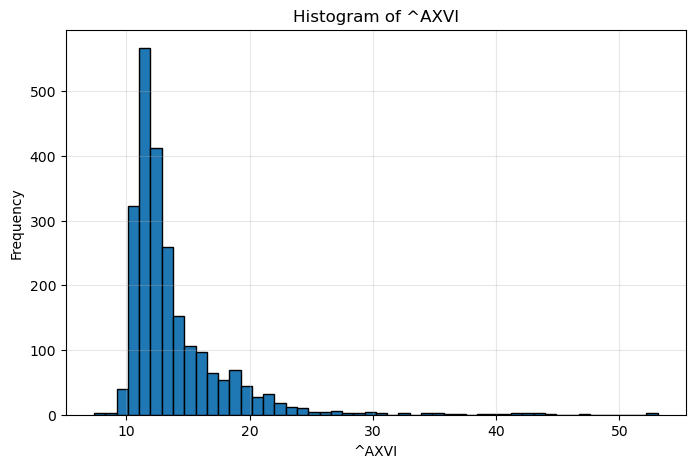

In [7]:
np.random.seed(SEED)

if PLOT_GRAPH ==True:
    plot_column_histograms(screened_prices['^AXVI'])

In [8]:
def hmm_feature_engineering(prices,returns,n_states):
    # Fady: HMM basic feature engineering, use the two main features A-VIX and ASX 200 index
    df_p = prices.copy()
    df_r = returns.copy()

    clms=['^AXVI', 'STW.AX']
    df_p= df_p[clms]
    # Add returns
    df_p['^AXVI_r'] = df_r['^AXVI']
    df_p['STW.AX_r'] = df_r['STW.AX']

    # Fady: simple labeling of the training set
    # state 0 = low A-VIX, state 1 = medium A-VIX, state 2 = high A-VIX
    df_p['state'] =0

    if n_states == 3:
        df_p.loc[df_p['^AXVI']>13.5, 'state'] = 1
        df_p.loc[df_p['^AXVI']>17.5, 'state'] = 2

    if n_states == 2:
        df_p.loc[df_p['^AXVI']>16.75, 'state'] = 1

    # Add EMAs and rolling stats
    clms=['^AXVI', 'STW.AX','^AXVI_r','state']
    for clm in clms:
        #df_p['ema3_'+clm] = df_p[clm].ewm(span=3, adjust=False).mean()
        #df_p['ema3_'+clm].bfill(inplace=True)
        #df_p['ema3_pct_'+clm] = df_p['ema3_'+clm].pct_change()
        #df_p['ema3_pct_'+clm].bfill(inplace=True)

        df_p['ema10_'+clm] = df_p[clm].ewm(span=10, adjust=False).mean()
        df_p['ema10_'+clm] = df_p['ema10_'+clm].bfill()
        df_p['ema10_pct_'+clm] = df_p['ema10_'+clm].pct_change()
        df_p['ema10_pct_'+clm] = df_p['ema10_pct_'+clm].bfill()

        #df_p['std10_'+clm] = df_p[clm].rolling(window=10).std()
        #df_p['std10_'+clm].bfill(inplace=True)
        #df_p['std10_pct_'+clm] = df_p['std10_'+clm].pct_change()
        #df_p['std10_pct_'+clm].bfill(inplace=True)

        #df_p['std20_'+clm] = df_p[clm].rolling(window=20).std()
        #df_p['std20_'+clm].bfill(inplace=True)
        #df_p['std20_pct_'+clm] = df_p['std20_'+clm].pct_change()
        #df_p['std20_pct_'+clm].bfill(inplace=True)

    # handle unexpected values
    for clm in df_p.columns:
        finite_values = df_p.loc[np.isfinite(df_p[clm]),clm]
        df_p[clm] = df_p[clm].replace(np.inf,finite_values.max())
        df_p[clm] = df_p[clm].replace(-np.inf,finite_values.min())

    # Fady: smoothed version using EMA instead of actual value.
    df_p['state2'] =0
    if n_states == 3:
        df_p.loc[df_p['ema10_^AXVI']>13.5, 'state2'] = 1
        df_p.loc[df_p['ema10_^AXVI']>17.5, 'state2'] = 2
    if n_states == 2:
        df_p.loc[df_p['ema10_^AXVI']>16.75, 'state2'] = 1

    return df_p



 HMM accuracy:  0.8873720136518771





{'accuracy': 0.8873720136518771,
 'precision_macro': 0.7891373801916932,
 'recall_macro': 0.9334006054490414,
 'f1_macro': 0.8307210854579276,
 'confusion_matrix': array([[1718,  264],
        [   0,  362]]),
 'classification_report': '              precision    recall  f1-score   support\n\n           0       1.00      0.87      0.93      1982\n           1       0.58      1.00      0.73       362\n\n    accuracy                           0.89      2344\n   macro avg       0.79      0.93      0.83      2344\nweighted avg       0.93      0.89      0.90      2344\n'}






Number of state transitions: 24





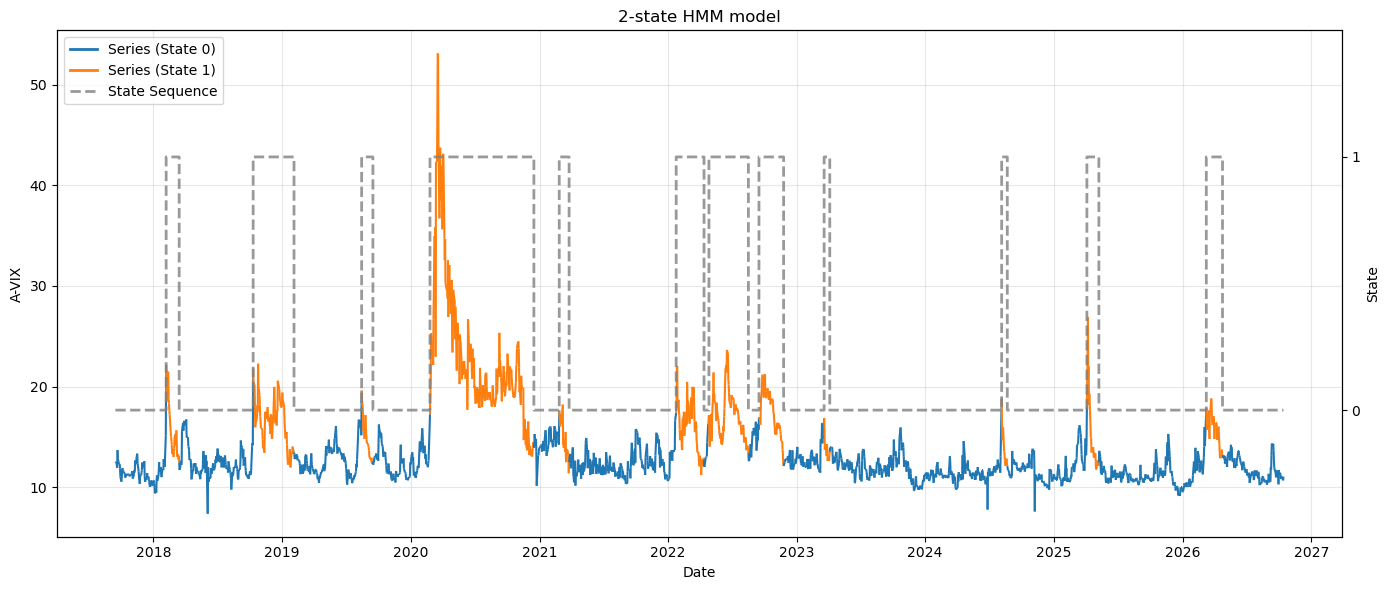

In [9]:
hmm_features=['state2','ema10_state','^AXVI','ema10_^AXVI']

# HMM modeling
HMM_STATES=2
df_p = hmm_feature_engineering(screened_prices,screened_returns,HMM_STATES)
hmm_baseline_model = train_hmm( emissions=df_p[hmm_features], n_states=HMM_STATES )
predicted_states = predict_states(  hmm_baseline_model,  df_p[hmm_features] )
predicted_states,state_map = reorder_states_by_avix_mean(predicted_states,df_p['^AXVI'].values)
df_p['pred_state'] = predicted_states


hmm_metrics = evaluate_state_predictions(
    df_p['state'].values,
    df_p['pred_state'].values
)


print('\n HMM accuracy: ', hmm_metrics['accuracy'])
print('\n\n')
display(hmm_metrics)
print('\n\n')

if PLOT_GRAPH ==True:
    plot_series_and_states(df_p['^AXVI'], df_p['pred_state'])
    


 HMM accuracy:  0.8843856655290102





{'accuracy': 0.8843856655290102,
 'precision_macro': 0.8552891797025435,
 'recall_macro': 0.8450304985088688,
 'f1_macro': 0.8497613351560719,
 'confusion_matrix': array([[1439,  100,    0],
        [ 101,  365,   25],
        [   1,   44,  269]]),
 'classification_report': '              precision    recall  f1-score   support\n\n           0       0.93      0.94      0.93      1539\n           1       0.72      0.74      0.73       491\n           2       0.91      0.86      0.88       314\n\n    accuracy                           0.88      2344\n   macro avg       0.86      0.85      0.85      2344\nweighted avg       0.89      0.88      0.88      2344\n'}






Number of state transitions: 66





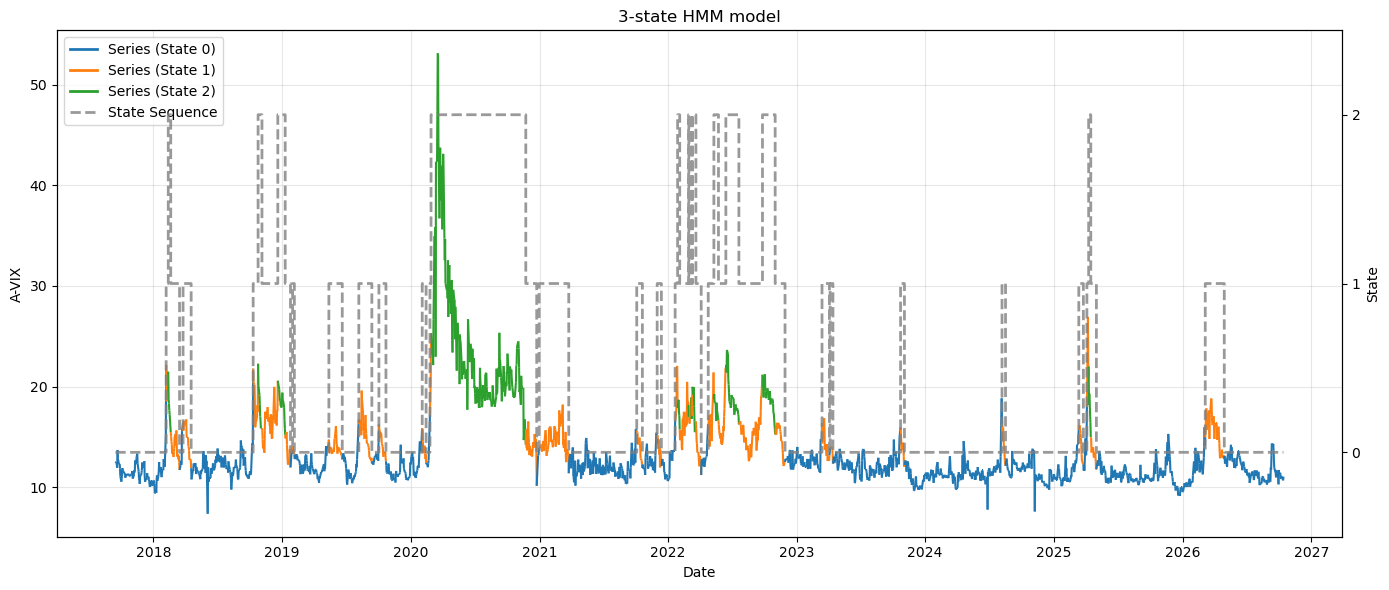

In [10]:
HMM_STATES=3
df_p = hmm_feature_engineering(screened_prices,screened_returns,HMM_STATES)
hmm_baseline_model = train_hmm( emissions=df_p[hmm_features], n_states=HMM_STATES )
predicted_states = predict_states(  hmm_baseline_model,  df_p[hmm_features] )
predicted_states,state_map = reorder_states_by_avix_mean(predicted_states,df_p['^AXVI'].values)
df_p['pred_state'] = predicted_states


hmm_metrics = evaluate_state_predictions(
    df_p['state'].values,
    df_p['pred_state'].values
)


print('\n HMM accuracy: ', hmm_metrics['accuracy'])
print('\n\n')
display(hmm_metrics)
print('\n\n')

if PLOT_GRAPH ==True:
    plot_series_and_states(df_p['^AXVI'], df_p['pred_state'])

### **4. Sliding window Walk forward loop**
For each of the three models we will apply the following steps:
1. Split the data and generate the train and test pairs
2. Fit the model on the training window data
3. Calculate the individual securties coeffcients from the factor coefficents.
4. Define portfolio weight constraints guided by the regressions coeffcients after normalisation.
5. Conduct QP weight optimsation to minise tracking error in training window subject to protfolio constraints.
6. Predict portfolio returns over the test window
7. Calculate tracking and trading metrics at the end of the test window

In [11]:
# Fady: define PCR, PLS, Elastic Net functions and the sliding window loop

def PCR_fit_predict(X_train,y_train,X_test,ncomponents):
    scaler = StandardScaler()
    Xtrn_scaled = scaler.fit_transform(X_train)
    Xtst_scaled = scaler.transform(X_test)

    # PCA
    pca = PCA()
    Xtrn_pca = pca.fit_transform(Xtrn_scaled)
    Xtst_pca = pca.transform(Xtst_scaled)

    n_components = max(1, min(ncomponents, Xtrn_pca.shape[1]))
    Xtrn_pca_selected = Xtrn_pca[:, :n_components]
    Xtst_pca_selected = Xtst_pca[:, :n_components]
    #print(f"Cumulative variance explained: {np.sum(pca.explained_variance_ratio_[:n_components]):.3f}")

    #PCR
    pcr = LinearRegression(fit_intercept=True)
    pcr.fit(Xtrn_pca_selected, y_train)
    y_pred = pcr.predict(Xtst_pca_selected)

    return y_pred,n_components,pcr,pca,scaler


def PLS_fit_predict(X_train,y_train,X_test,ncomponents):
    ncomponents = max(1, min(ncomponents, X_train.shape[1], len(X_train)))

    # PLSRegression centres X and y and therefore fits an intercept.
    pls = PLSRegression(n_components=ncomponents, scale=True)
    pls.fit(X_train, y_train)
    y_pred = pls.predict(X_test).ravel()

    return y_pred,pls


def EN_fit_predict(X_train,y_train,X_test):
    scaler = StandardScaler()
    Xtrn_scaled = scaler.fit_transform(X_train)
    Xtst_scaled = scaler.transform(X_test)

    # Elastic Net
    model = ElasticNetCV(
        l1_ratio=[0.001, 0.005, 0.01],
        alphas = [0.005, 0.01],
        cv=3,
        max_iter=200,
        fit_intercept=True,
        random_state=SEED  )

    model.fit(Xtrn_scaled, y_train)
    y_pred = model.predict(Xtst_scaled)
    '''
    print("\nEN Hyperparameters")
    print(f"Alpha    = {model.alpha_:.5f}")
    print(f"L1 Ratio = {model.l1_ratio_:.3f}")
    '''
    return y_pred,model,scaler


def convert_to_security_coefficients(title,model,trn_features,scaler=None,pca=None):

    features = list(trn_features)

    if title == 'PCR':
        pc_coefficients = np.asarray(model.coef_).ravel()
        pca_components = pca.components_[:len(pc_coefficients),:]

        scaled_coefficients = np.dot(pca_components.T,pc_coefficients)
        security_coefficients = scaled_coefficients/scaler.scale_

        intercept = float(np.asarray(model.intercept_).ravel()[0])
        intercept -= np.dot(pca.mean_,scaled_coefficients)
        intercept -= np.dot(scaler.mean_,security_coefficients)

    elif title == 'PLS':
        # Convert PLS latent-factor coefficients back to the original securities.
        factor_coefficients = np.dot(model.x_rotations_,model.y_loadings_.T)
        security_coefficients = (
            (factor_coefficients*model._y_std).T/model._x_std
        ).ravel()

        intercept = float(np.asarray(model._y_mean).ravel()[0])
        intercept -= np.dot(model._x_mean,security_coefficients)

    elif title == 'EN':
        security_coefficients = np.asarray(model.coef_).ravel()/scaler.scale_

        intercept = float(np.asarray(model.intercept_).ravel()[0])
        intercept -= np.dot(scaler.mean_,security_coefficients)

    else:
        raise ValueError("title must be 'PCR', 'PLS' or 'EN'")

    coefficients = pd.DataFrame(
        [list(security_coefficients)+[intercept]],
        columns=features+['CONST']
    )

    return coefficients


def predict_from_securities(X_test,coefficients):

    security_columns = [clm for clm in coefficients.columns if clm != 'CONST']
    security_coefficients = coefficients[security_columns].iloc[0].values
    intercept = coefficients['CONST'].iloc[0]

    y_pred = np.dot(X_test[security_columns].values,security_coefficients)+intercept

    return y_pred


# Fady: Cache of model fits so grid-search iterations re-use identical fits.
FIT_CACHE = {}


def fit_predict_securities(title,X_train,y_train,X_test,ncomponents=20,window_key=None):

    # Fady: fit the model, convert its coefficients to individual securities and check
    # that the security coefficients give the same test-window prediction, result can be cached.
    if title in ['PCR','PLS']:
        model_parameter = ncomponents
    else:
        model_parameter = None

    cache_key = None if window_key is None else (title,model_parameter)+tuple(window_key)

    if cache_key is not None and cache_key in FIT_CACHE:
        ypred,coefficient_values,pcr_ncomponents = FIT_CACHE[cache_key]
        coefficients = pd.DataFrame([list(coefficient_values)],columns=list(X_train.columns)+['CONST'])

        return ypred,coefficients,pcr_ncomponents

    pcr_ncomponents = None

    if title == 'PCR':
        ypred,pcr_ncomponents,pcr,pca,scaler = PCR_fit_predict(X_train,y_train,X_test,ncomponents)

        coefficients = convert_to_security_coefficients(
            'PCR',pcr,X_train.columns,scaler=scaler,pca=pca
        )

    elif title == 'PLS':
        ypred,pls = PLS_fit_predict(X_train,y_train,X_test,ncomponents)

        coefficients = convert_to_security_coefficients(
            'PLS',pls,X_train.columns
        )

    elif title == 'EN':
        ypred,model,scaler = EN_fit_predict(X_train,y_train,X_test)

        coefficients = convert_to_security_coefficients(
            'EN',model,X_train.columns,scaler=scaler
        )

    else:
        raise ValueError("title must be 'PCR', 'PLS' or 'EN'")

    ypred_from_securities = predict_from_securities(X_test,coefficients)

    if not np.allclose(ypred,ypred_from_securities,rtol=1e-7,atol=1e-10):
        raise RuntimeError(title+" security coefficient conversion changed ypred.")

    if cache_key is not None:
        FIT_CACHE[cache_key] = (ypred,coefficients.iloc[0].values.copy(),pcr_ncomponents)

    return ypred,coefficients,pcr_ncomponents



def coefficients_to_weights(coefficients,gross_exposure=1.0,min_abs_weight=None):

    # Fady: CONST is the regression intercept and is not a portfolio holding.
    if min_abs_weight is None:
        min_abs_weight = MIN_ABS_WEIGHT

    security_columns = [clm for clm in coefficients.columns if clm != 'CONST']
    beta = coefficients[security_columns].iloc[0].values.astype(float).copy()

    if min_abs_weight < 0:
        raise ValueError("min_abs_weight cannot be negative.")

    # Fady: remove very small security weights and re-normalise the remaining
    # coefficients. Repeat because re-normalisation changes all remaining weights.
    while True:
        gross_beta = np.sum(np.abs(beta))

        if gross_beta == 0:
            raise ValueError("Security coefficients cannot all be zero.")

        risky_weights = gross_exposure*beta/gross_beta

        small_weights = (np.abs(risky_weights) < min_abs_weight) & (beta != 0)

        if not np.any(small_weights):
            break

        beta[small_weights] = 0.0

    # AAA.AX is the residual cash position so that total portfolio weight = 1
    cash_weight = 1.0 - np.sum(risky_weights)

    weights = pd.DataFrame(
        [list(risky_weights)+[cash_weight]],
        columns=security_columns+['AAA.AX']
    )

    return weights


# one cvxpy problem per number of securities and objective type (TE only, or return - TE),
# built once and re-solved with new parameter values. cvxpy then skips re-compiling it for every window.
QP_PROBLEMS = {}


def build_QP_problem(n_securities,return_term):

    # Fady: the error term follows OBJECTIVE_OPTION, as in compute_objective(), with the gross returns
    # of the training window (the net returns are not known before the weights):
    #   e_t = R_t - I_t,  R_t = sum_i w_i r_it + a c_t (gross portfolio return),  TE = std(e) (ddof=1)
    # return_term=False (option 4): minimise TE, a QP:
    #   min ||R_c [w,a] - Q_c'y_c||^2  =  (T-1)*TE^2 - kappa
    # return_term=True (options 1-3): maximise return - k*a*TE*sqrt(252), a second-order cone program:
    #   min ||[R_c [w,a] - Q_c'y_c, sqrt(kappa)]|| - mean_returns'[w,a]
    #   ||[R_c [w,a] - Q_c'y_c, sqrt(kappa)]|| = sqrt(sum((e_t - mean(e))^2)) = sqrt(T-1)*TE exactly.
    # R_c, Q_c'y_c and kappa come from the QR factor of the demeaned training data, so the problem size
    # (n_securities+1 rows) does not depend on the number of observations. The TE weight and the return
    # slope are folded into the parameter values. Built once per number of securities and objective
    # type and re-solved with new parameter values (DPP), so cvxpy does not re-compile it.
    weights_qp = cp.Variable(n_securities)
    aaa_weight_qp = cp.Variable()

    R_securities = cp.Parameter((n_securities+1,n_securities))
    R_aaa = cp.Parameter(n_securities+1)
    Qt_y = cp.Parameter(n_securities+1)
    lower_bounds = cp.Parameter(n_securities)
    upper_bounds = cp.Parameter(n_securities)
    gross_exposure = cp.Parameter(nonneg=True)

    tracking_error = R_securities@weights_qp + R_aaa*aaa_weight_qp - Qt_y

    qp_problem = {}

    if return_term:
        sqrt_kappa = cp.Parameter(1,nonneg=True)
        mean_securities = cp.Parameter(n_securities)
        mean_aaa = cp.Parameter()

        objective = cp.Minimize(
            cp.norm(cp.hstack([tracking_error,sqrt_kappa]),2)
            - (mean_securities@weights_qp + mean_aaa*aaa_weight_qp)
        )

        qp_problem['sqrt_kappa'] = sqrt_kappa
        qp_problem['mean_securities'] = mean_securities
        qp_problem['mean_aaa'] = mean_aaa
    else:
        objective = cp.Minimize(cp.sum_squares(tracking_error))

    constraints = [
        cp.sum(weights_qp)+aaa_weight_qp == 1,
        cp.norm1(weights_qp) <= gross_exposure,
        weights_qp >= lower_bounds,
        weights_qp <= upper_bounds,
    ]

    problem = cp.Problem(objective,constraints)

    # warnings are filtered globally, so report here if cvxpy cannot reuse the compiled problem
    # (results are still correct, it is only slower)
    if not problem.is_dpp():
        print("Note: the QP is not DPP-compliant, cvxpy will re-compile it for every solve.")

    qp_problem.update({
        'problem': problem,
        'weights_qp': weights_qp,
        'aaa_weight_qp': aaa_weight_qp,
        'R_securities': R_securities,
        'R_aaa': R_aaa,
        'Qt_y': Qt_y,
        'lower_bounds': lower_bounds,
        'upper_bounds': upper_bounds,
        'gross_exposure': gross_exposure,
    })

    return qp_problem


def qp_weight_bounds(initial_weights):

    # Fady: each risky weight may move within +/- WEIGHT_DEVIATION of its starting value, but
    # - a non-zero weight cannot fall below MIN_ABS_WEIGHT in absolute value (every non-zero
    #   starting weight is already >= MIN_ABS_WEIGHT, so the starting weights stay feasible)
    # - a security removed by coefficients_to_weights() (zero weight) stays at zero
    lower_bounds = initial_weights - WEIGHT_DEVIATION*np.abs(initial_weights)
    upper_bounds = initial_weights + WEIGHT_DEVIATION*np.abs(initial_weights)

    lower_bounds = np.where(initial_weights > 0,np.maximum(lower_bounds,MIN_ABS_WEIGHT),lower_bounds)
    upper_bounds = np.where(initial_weights < 0,np.minimum(upper_bounds,-MIN_ABS_WEIGHT),upper_bounds)

    zero_weights = np.isclose(initial_weights,0.0)
    lower_bounds[zero_weights] = 0.0
    upper_bounds[zero_weights] = 0.0

    return lower_bounds,upper_bounds


def qp_least_squares_factor(X_values,aaa_values,y_values):

    # sum((y - X w - aaa a)^2) = sum((R [w,a] - Q'y)^2) + constant, with [X, aaa] = Q R,
    # so the QP objective has n_securities+1 rows whatever the number of observations.
    # Zero rows are added when there are fewer observations than unknowns (small HMM states);
    # they do not change the sum of squares.
    design = np.column_stack([X_values,aaa_values])
    n_missing_rows = design.shape[1]-len(design)

    if n_missing_rows > 0:
        design = np.vstack([design,np.zeros((n_missing_rows,design.shape[1]))])
        y_values = np.concatenate([y_values,np.zeros(n_missing_rows)])

    Q,R = np.linalg.qr(design)

    return R,Q.T@y_values


def QP_optimize_weights(X_train,y_train,aaa_returns,portfolio_weights,gross_exposure=1.0):

    # Fady: optimise the statistically derived weights within the bounds of qp_weight_bounds()
    features = [clm for clm in portfolio_weights.columns if clm != 'AAA.AX']

    initial_weights = portfolio_weights[features].iloc[0].values.astype(float)

    X_values = X_train[features].values
    y_values = np.asarray(y_train).ravel()
    aaa_values = np.asarray(aaa_returns).ravel()

    if len(X_values) != len(y_values) or len(y_values) != len(aaa_values):
        raise ValueError("X_train, y_train and aaa_returns must have the same number of observations.")

    if len(y_values) < 2:
        raise ValueError("At least two observations are required to optimise the tracking error.")

    lower_bounds,upper_bounds = qp_weight_bounds(initial_weights)

    # G_M115: error term of OBJECTIVE_OPTION (see build_QP_problem), with the gross returns.
    # Reverted to the original least-squares formulation using the raw (non-demeaned) data.
    # For A = [X_values, aaa_values], QR gives:
    #     ||A w - y||^2 = ||R w - Q.T y||^2 + kappa
    # where kappa is the squared norm of the component of y orthogonal to col(A).
    T = len(y_values)
    X_mean = X_values.mean(axis=0)
    aaa_mean = aaa_values.mean()

    R,Qt_y = qp_least_squares_factor(X_values,aaa_values,y_values)
    kappa = max(np.sum(y_values**2)-np.sum(Qt_y**2),0.0)

    # same TE weights k as compute_objective() (with its default a = 1): options 1, 2, 3
    te_weights = {1: A_1, 2: A_2, 3: A_3}

    if OBJECTIVE_OPTION in te_weights:
        return_term = True
        # maximise return - k*annualised raw tracking-residual norm.
        # With the reverted non-demeaned least-squares formulation, this uses
        # ||e||/sqrt(T-1), so a non-zero mean tracking error is also penalised.
        te_weight = te_weights[OBJECTIVE_OPTION]*np.sqrt(252)/np.sqrt(T-1)
        # the annualised return (1+m)^252-1 is replaced by its tangent at the mean gross return m0
        # of the starting weights (the bounds keep the weights close to them), slope 252*(1+m0)^251
        initial_aaa_weight = float(portfolio_weights['AAA.AX'].iloc[0])
        m0 = np.mean(X_values@initial_weights+aaa_values*initial_aaa_weight)
        return_slope = 252*(1+m0)**251
    elif OBJECTIVE_OPTION == 4:
        return_term = False
        te_weight = 1.0
    else:
        raise ValueError("OBJECTIVE_OPTION must be 1, 2, 3 or 4")

    if (len(features),return_term) not in QP_PROBLEMS:
        QP_PROBLEMS[(len(features),return_term)] = build_QP_problem(len(features),return_term)

    qp_problem = QP_PROBLEMS[(len(features),return_term)]
    qp_problem['R_securities'].value = te_weight*R[:,:-1]
    qp_problem['R_aaa'].value = te_weight*R[:,-1]
    qp_problem['Qt_y'].value = te_weight*Qt_y

    if return_term:
        qp_problem['sqrt_kappa'].value = np.array([te_weight*np.sqrt(kappa)])
        qp_problem['mean_securities'].value = return_slope*X_mean
        qp_problem['mean_aaa'].value = return_slope*aaa_mean

    qp_problem['lower_bounds'].value = lower_bounds
    qp_problem['upper_bounds'].value = upper_bounds
    qp_problem['gross_exposure'].value = gross_exposure

    problem = qp_problem['problem']
    #problem.solve(warm_start=True)
    problem.solve()

    if problem.status not in ['optimal','optimal_inaccurate']:
        raise RuntimeError("QP optimisation failed with status: "+str(problem.status))

    risky_qp_weights = np.clip(np.asarray(qp_problem['weights_qp'].value).ravel(),lower_bounds,upper_bounds)
    aaa_qp_weight = 1.0-np.sum(risky_qp_weights)

    qp_weights = pd.DataFrame(
        [list(risky_qp_weights)+[float(aaa_qp_weight)]],
        columns=features+['AAA.AX']
    )

    return qp_weights


def execute_portfolio_trading(portfolio_weights,previous_weights=None,transaction_cost=None,
                              rebalance_opportunities=None,min_rel_weight_chng=None):

    # Fady: portfolio_weights has one row per test day. The first day is compared with the last
    # portfolio of the previous test window (or 100% AAA.AX for the first window). All weight
    # changes are executed, so each day's portfolio is the next day's previous portfolio.
    #
    # Only the risky securities are traded. AAA.AX is a proxy for a cash savings account, so
    # moving money in or out of it is a free transfer, not a trade.
    #

    if transaction_cost is None:
        transaction_cost = TRANSACTION_COST
    if min_rel_weight_chng is None:
        min_rel_weight_chng = MIN_REL_WEIGHT_CHANGE

    if min_rel_weight_chng < 0:
        raise ValueError("min_rel_weight_chng cannot be negative.")

    risky_columns = [clm for clm in portfolio_weights.columns if clm != 'AAA.AX']
    weights = portfolio_weights[risky_columns].values.astype(float)

    if previous_weights is None:
        previous = np.zeros(len(risky_columns))
    else:
        previous = previous_weights.iloc[-1].reindex(risky_columns).values.astype(float)

    if rebalance_opportunities is None:
        rebalance_opportunities = np.zeros(len(weights),dtype=bool)
        if len(weights) > 0:
            rebalance_opportunities[0] = True

    rebalance_opportunities = np.asarray(rebalance_opportunities,dtype=bool)

    if len(rebalance_opportunities) != len(weights):
        raise ValueError("rebalance_opportunities must have the same length as portfolio_weights.")

    # previous day's weights for every test day
    previous_values = np.vstack([previous,weights[:-1]])[:len(weights)]
    weight_change = weights-previous_values

    weight_tolerance = 1e-8
    traded = (np.abs(weight_change) > weight_tolerance) & (np.abs(weight_change) >= min_rel_weight_chng*np.abs(previous_values))
    charged_weight_change = np.where(traded,weight_change,0.0)

    # summed day by day (1-D sums) so the results are exactly the same as in earlier versions
    risky_turnover = np.array([np.sum(np.abs(day_change)) for day_change in charged_weight_change])
    risky_weight_change = np.array([np.sum(np.abs(day_change)) for day_change in weight_change])

    trading = pd.DataFrame(
        {
            'risky_turnover': risky_turnover,
            'risky_weight_change': risky_weight_change,
            'transaction_cost': transaction_cost*risky_turnover,
            'rebalance_required': np.any(traded,axis=1),
            'rebalance_opportunity': rebalance_opportunities,
            'number_trades': np.sum(traded,axis=1),
            # QP weights can sit exactly at MIN_ABS_WEIGHT, hence >=
            'active_holdings': np.sum(np.abs(weights) >= MIN_ABS_WEIGHT,axis=1),
        },
        index=portfolio_weights.index
    )

    return trading


def compute_trading_metrics(title,trading,net_returns,gross_returns,index_retruns,verbose=True,risk_free_retruns=None):

    # Fady: index_retruns are the A-VIX returns of the same test days
    # risk_free_retruns default to the AAA.AX returns of the same test days.
    if len(trading) == 0:
        raise ValueError("trading cannot be empty.")

    number_days = len(trading)

    net_returns = np.asarray(net_returns,dtype=np.float64)
    gross_returns = np.asarray(gross_returns,dtype=np.float64)
    index_retruns = np.asarray(index_retruns,dtype=np.float64)

    if len(index_retruns) != number_days:
        raise ValueError("index_retruns must cover the same test days as trading.")

    excess_retruns = net_returns-index_retruns

    net_annualised_returns = ((1+np.mean(net_returns))**252) -1 
    gross_annualised_returns = ((1+np.mean(gross_returns))**252) -1 
    excess_annualised_retruns = ((1+np.mean(excess_retruns))**252) -1  

    # transaction cost drag relative to portfolio NAV; the rest of gross - net is the short borrow cost
    annualised_total_cost = gross_annualised_returns-net_annualised_returns
    total_daily_cost = np.sum(gross_returns-net_returns)

    if total_daily_cost > 0:
        transaction_cost_share = trading['transaction_cost'].sum()/total_daily_cost
    else:
        transaction_cost_share = 0.0

    annualised_transaction_cost = annualised_total_cost*transaction_cost_share
    annualised_short_borrow_cost = annualised_total_cost-annualised_transaction_cost

    # Fady: turnover ratio = annualised turnover of the risky securities
    total_risky_turnover = trading['risky_turnover'].sum()
    turnover_ratio = total_risky_turnover*252/number_days
    maximum_daily_turnover = trading['risky_turnover'].max()

    rebalance_days = int(round(trading['rebalance_required'].sum()*252/number_days,0))
    rebalance_opportunities = int(round(trading['rebalance_opportunity'].sum()*252/number_days,0))
    number_trades = int(round(trading['number_trades'].sum()*252/number_days,0))
    average_active_holdings = int(round(trading['active_holdings'].mean(),0))
    
    # Fady: Portfolio VaR 95%, Portfolio CVaR 95%
    alpha = 0.95
    portfolio_loss = -np.asarray(net_returns)
    portfolio_VaR95 = np.quantile( portfolio_loss, alpha, method='inverted_cdf')
    portfolio_CVaR95 = np.mean( portfolio_loss[portfolio_loss >= portfolio_VaR95])

    # Dhingra et al. (2026)
    if risk_free_retruns is None:
        risk_free_retruns = screened_returns.loc[trading.index,'AAA.AX'].values

    risk_free_retruns = np.asarray(risk_free_retruns,dtype=np.float64)

    if len(risk_free_retruns) != number_days:
        raise ValueError("risk_free_retruns must cover the same test days as trading.")

    mean_return_Dhingra = np.mean(net_returns)
    min_return_Dhingra = np.min(net_returns)
    max_return_Dhingra = np.max(net_returns)
    std_Dhingra = np.std(net_returns,ddof=1)*np.sqrt(252)

    std_daily = np.std(net_returns,ddof=1)

    # drawdown from the running peak of the cumulative wealth W_t = prod(1+r)
    wealth = np.cumprod(1+net_returns)
    peak_wealth = np.maximum.accumulate(wealth)
    average_drawdown_Dhingra = np.mean(np.abs((wealth-peak_wealth)/peak_wealth))
    max_drawdown_Dhingra = np.max(np.abs((wealth-peak_wealth)/peak_wealth))

    excess_rf = np.mean(net_returns)-np.mean(risk_free_retruns)
    negative_returns = net_returns[net_returns < 0]
    beta_Dhingra = np.cov(net_returns,index_retruns,ddof=1)[0][1]/np.var(index_retruns,ddof=1)

    sharpe = (excess_rf/std_daily)*np.sqrt(252)
    # sigma_d: standard deviation of the negative returns
    sortino_Dhingra = excess_rf/np.std(negative_returns,ddof=1) if len(negative_returns) > 1 else np.nan
    treynor_Dhingra = excess_rf/beta_Dhingra
    # mean excess return over the index / tracking error (std of the active return)
    information_ratio_Dhingra = np.mean(excess_retruns)/np.std(excess_retruns,ddof=1)

    # turnover TR: average sum of absolute risky weight changes per rebalancing window,
    # excluding the initial build from cash (AAA.AX cash moves are not trades)

    rebalance_windows = int(trading['rebalance_opportunity'].sum())
    if rebalance_windows > 1:
        TR_Dhingra = trading['risky_weight_change'].iloc[1:].sum()/(rebalance_windows-1)
    else:
        TR_Dhingra = 0.0

    if verbose:
        print("\n"+"-" * 40)
        print("\t"+title)
        print("-" * 40)
        print(f"Net Returns\t\t: {net_annualised_returns:.5f}")
        print(f"Volatility\t: {std_Dhingra:.5f}")
        print(f"Gross Returns\t\t: {gross_annualised_returns:.5f}")
        print(f"Transaction Cost\t: {annualised_transaction_cost:.5f}")
        print(f"Short borrow Cost\t: {annualised_short_borrow_cost:.5f}")
        #print(f"Total Cost\t\t\t: {annualised_total_cost:.5f}")
        print(f"Turnover\t\t\t: {turnover_ratio:.5f}")
        print(f"Max daily Turnover\t\t\t: {maximum_daily_turnover:.5f}")
        print(f"TR (Dhingra)\t\t\t\t: {TR_Dhingra:.5f}")
        print(f"Average drawdown\t: {average_drawdown_Dhingra:.5f}")
        print(f"Max drawdown\t: {max_drawdown_Dhingra:.5f}")
        print(f"Sharpe\t\t: {sharpe:.5f}")
        print(f"Daily VaR 95%\t: {portfolio_VaR95:.5f}")
        print(f"Daily CVaR 95%\t: {portfolio_CVaR95:.5f}") 
        print(f"Rebalance days\t\t\t\t: {rebalance_days}")
        #print(f"Rebalance opportunities (annual)\t\t: {rebalance_opportunities}")
        print(f"Number of trades\t\t\t: {number_trades}")
        print(f"Average Holdings\t\t\t: {average_active_holdings}")
        print("-" * 40+'\n')

    metrics = {
        'gross_annualised_returns':gross_annualised_returns,
        'net_annualised_returns':net_annualised_returns,
        'annualised_transaction_cost': annualised_transaction_cost,
        'annualised_short_borrow_cost': annualised_short_borrow_cost,
        'annualised_total_cost': annualised_total_cost,
        'turnover_ratio': turnover_ratio,
        'total_risky_turnover': total_risky_turnover,
        'rebalance_days': rebalance_days,
        'rebalance_opportunities': rebalance_opportunities,
        'number_trades': number_trades,
        'maximum_daily_turnover': maximum_daily_turnover,
        'average_active_holdings': average_active_holdings,
        'Std_Dhingra': std_Dhingra,
        'TR_Dhingra': TR_Dhingra,
    }

    metrics = pd.DataFrame(metrics.items(), columns = ["Metric", "Value"])

    return metrics


def compute_portfolio_returns(qp_weights,X_test,aaa_returns,short_borrow_rate=SHORT_BORROW_RATE,transaction_costs=None):

    # Fady: weights may be one constant row for the whole test window or
    # one row per day when the HMM state changes inside the test window.
    features = [clm for clm in qp_weights.columns if clm != 'AAA.AX']

    X_values = X_test[features].values
    aaa_values = np.asarray(aaa_returns).ravel()

    if len(X_values) != len(aaa_values):
        raise ValueError("X_test and aaa_returns must have the same number of observations.")

    if len(qp_weights) == 1:
        risky_weights = np.tile(
            qp_weights[features].iloc[0].values.astype(float),
            (len(X_test),1)
        )
        aaa_weights = np.repeat(
            float(qp_weights['AAA.AX'].iloc[0]),
            len(X_test)
        )

    elif len(qp_weights) == len(X_test):
        risky_weights = qp_weights[features].values.astype(float)
        aaa_weights = qp_weights['AAA.AX'].values.astype(float)

    else:
        raise ValueError("qp_weights must contain either one row or one row per test observation.")

    # Cash component remains invested in AAA.AX.
    portfolio_return = np.sum(X_values*risky_weights,axis=1) + aaa_values*aaa_weights

    # Apply daily short borrowing cost to the short security exposure.
    total_short_positions = np.sum(np.abs(np.minimum(risky_weights,0)),axis=1)
    daily_short_borrow_rate = short_borrow_rate/252
    short_borrow_cost = total_short_positions*daily_short_borrow_rate

    if transaction_costs is None:
        transaction_costs = np.zeros(len(X_test))
    else:
        transaction_costs = np.asarray(transaction_costs).ravel()

        if len(transaction_costs) != len(X_test):
            raise ValueError("transaction_costs must have the same number of observations as X_test.")

    y_pred_portfolio = portfolio_return-short_borrow_cost-transaction_costs

    return y_pred_portfolio, portfolio_return


def compute_tracking_metrics(title,y_test,y_pred):
    y_test = np.asarray(y_test).ravel()
    y_pred = np.asarray(y_pred).ravel()

    if len(y_test) != len(y_pred):
        raise ValueError("y_test and y_pred must have the same length.")
    if len(y_test) < 2:
        raise ValueError("At least two observations are required to calculate tracking metrics.")

    T = len(y_test)
    tracking_error = y_pred - y_test
    demeaned_error  = tracking_error - np.mean(tracking_error)
    #index_minus_portfolio = y_test - y_pred

    #r2 = r2_score(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))*np.sqrt(252)
    mae = mean_absolute_error(y_test, y_pred)*np.sqrt(252)
    TESD  =  np.sqrt(np.sum(demeaned_error**2)/(T-1))*np.sqrt(252)
    ME = np.mean(tracking_error)*(252)
    
    corr_ret = np.corrcoef(y_test,y_pred)
    corr_ret=corr_ret[0][1]
    y_test_cumulative = np.cumprod(1+np.array(y_test))
    y_pred_cumulative = np.cumprod(1+np.array(y_pred))
    corr_cumulative =  np.corrcoef(y_test_cumulative,y_pred_cumulative)
    corr_cumulative=corr_cumulative[0][1]

    # Dorocakova (2017), p.159
    TE1_Dorocakova = np.sqrt(np.sum(tracking_error**2)/(T-1))
    TE2_Dorocakova = np.mean(np.abs(tracking_error))
    RD_Dorocakova = np.abs(tracking_error)
    TE3_Dorocakova = np.std(RD_Dorocakova, ddof=1)
    
    
    # Dhingra et al. (2026), pp.13-15
    index_minus_portfolio = -1*tracking_error
    TEV_Dhingra = np.var(tracking_error, ddof=0)
    TESD_Dhingra = np.sqrt(TEV_Dhingra)
    alpha_TE_Dhingra = 2
    TE_alpha_Dhingra = (1/T)*np.sum(np.abs(index_minus_portfolio)**alpha_TE_Dhingra)**(1/alpha_TE_Dhingra)
    RMSE_Dhingra = np.sqrt(np.mean(index_minus_portfolio**2))
    MSE_Dhingra = np.mean(index_minus_portfolio**2)
    SES_Dhingra = (np.sum(index_minus_portfolio)**2)/T
    MAD_Dhingra = np.mean(np.abs(index_minus_portfolio))
    MADD_Dhingra = np.sum(np.maximum(index_minus_portfolio,0))
    MinMax_Dhingra = np.max(np.abs(index_minus_portfolio))
    DMinMax_Dhingra = np.max(np.maximum(index_minus_portfolio,0))
    TE_Dhingra = np.std(tracking_error, ddof=1)
    LSR_beta_Dhingra = np.cov(y_pred,y_test,ddof=1)[0][1]/np.var(y_test,ddof=1)
    LSR_alpha_Dhingra = np.mean(y_pred)-LSR_beta_Dhingra*np.mean(y_test)
    
    alpha_Dhingra = [0.9, 0.75, 0.5, 0.1, 0.01]
    
    def empirical_cvar(values,alpha):

        var = np.quantile(values,alpha,method='inverted_cdf')
        return var + np.mean(np.maximum(values-var,0))/(1-alpha)
    
    MCVaR_Dhingra = np.mean([empirical_cvar(index_minus_portfolio,alpha) for alpha in alpha_Dhingra])
    MCVaR_upper_Dhingra = np.mean([empirical_cvar(-index_minus_portfolio,alpha) for alpha in alpha_Dhingra])
    TMCVaR_Dhingra = 0.5*MCVaR_upper_Dhingra + 0.5*MCVaR_Dhingra

    print("\n"+"-" * 40)
    print("\t"+title)
    print("-" * 40)
    
    #print(f"R²   : {r2:.4f}")
    
    print(f"RMSE\t\t\t\t\t\t: {rmse:.5f}")
    print(f"TESD\t\t\t\t\t\t\t: {TESD:.5f}")
    print(f"MAE\t\t\t\t\t\t\t: {mae:.5f}")
    print(f"ME\t\t\t\t\t\t\t: {ME:.5f}")

    #print(f"TE1 : {TE1_Dorocakova:.5f}")
    #print(f"TE2 : {TE2_Dorocakova:.5f}")
    #print(f"TE3 : {TE3_Dorocakova:.5f}")

    #print(f"TE\t\t\t\t\t\t\t: {TE_Dhingra:.5f}")
    #print(f"TESD\t\t\t\t\t\t: {TESD_Dhingra:.5f}")
    #print(f"TEV\t\t\t\t\t\t\t: {TEV_Dhingra:.5f}")  
    
    
    print(f"Corr\t\t\t\t\t\t: {corr_ret:.5f}")
    print("-" * 40+'\n')
    
    metrics = {
        'TESD': TESD,
        'MAE': mae,
        'RMSE': rmse,
        'ME': ME,
        
        'TE1': TE1_Dorocakova,
        'TE2': TE2_Dorocakova,
        'TE3': TE3_Dorocakova,
        'Corr_ret':corr_ret,
        
        'TE_Dhingra': TE_Dhingra,
        'TEV_Dhingra': TEV_Dhingra,
        'TESD_Dhingra': TESD_Dhingra,
        'SES_Dhingra': SES_Dhingra,
    }
    
    metrics = pd.DataFrame(metrics.items(), columns = ["Metric", "Value"])

    return metrics

def fit_qp_portfolio(title,X_train,y_train,X_test,ncomponents,window_key):

    # Fady: model fit -> security weights -> QP-optimised weights 
    ypred,coefficients,ncomponents_used = fit_predict_securities(
        title,X_train,y_train,X_test,ncomponents,window_key=window_key
    )

    portfolio_weights = coefficients_to_weights(coefficients,gross_exposure=1.0)

    aaa_train = screened_returns.loc[X_train.index,'AAA.AX']
    qp_weights = QP_optimize_weights(
        X_train,y_train,aaa_train,portfolio_weights,gross_exposure=1.0
    )

    return ypred,ncomponents_used,coefficients,portfolio_weights,qp_weights


def trade_portfolio(daily_qp_weights,previous_qp_weights,X_test,rebalance_opportunities):

    # Fady: trading (costs) and daily net and gross portfolio returns for one test window
    trading = execute_portfolio_trading(
        daily_qp_weights,previous_qp_weights,rebalance_opportunities=rebalance_opportunities
    )

    aaa_test = screened_returns.loc[X_test.index,'AAA.AX']
    ypred_portfolio,ypred_portfolio_gross = compute_portfolio_returns(
        daily_qp_weights,X_test,aaa_test,short_borrow_rate=SHORT_BORROW_RATE,
        transaction_costs=trading['transaction_cost'].values
    )

    return trading,ypred_portfolio,ypred_portfolio_gross


def sliding_walk_forward(title,X_df,y_df,orig_price,train_window_size,test_window_size,ncomponents=None):

    if ncomponents is None:
        ncomponents = N_COMPONENTS

    y_pred = []
    y_pred_portfolio = []  # net portfolio returns (after costs)
    y_pred_portfolio_gross = [] #gross portfolio returns
    pcr_ncomponents = []
    trading_records = []
    holdings_records = []
    previous_qp_weights = None

    splits=walk_forward_sliding_window(len(X_df), train_window_size, test_window_size)

    for split in splits.itertuples():

        X_train = X_df[split.train_start:split.train_end + 1]
        y_train = y_df[split.train_start:split.train_end + 1]
        X_test  = X_df[split.test_start:split.test_end + 1]

        # window_key identifies the window for the fit cache
        window_key = ('sliding',split.train_start,split.train_end,split.test_start,split.test_end)

        ypred,ncomponents_used,coefficients,portfolio_weights,qp_weights = fit_qp_portfolio(
            title,X_train,y_train,X_test,ncomponents,window_key
        )

        if ncomponents_used is not None:
            pcr_ncomponents.append(ncomponents_used)

        # Fady: sliding-window QP weights stay unchanged during the test window.
        daily_qp_weights = pd.DataFrame(
            np.tile(qp_weights.iloc[0].values,(len(X_test),1)),
            index=X_test.index,
            columns=qp_weights.columns
        )

        rebalance_opportunities = np.zeros(len(X_test),dtype=bool)
        rebalance_opportunities[0] = True

        trading,ypred_portfolio,ypred_portfolio_gross = trade_portfolio(
            daily_qp_weights,previous_qp_weights,X_test,rebalance_opportunities
        )
        trading_records.append(trading)

        previous_qp_weights = daily_qp_weights.iloc[[-1]].copy()

        # G_M110: weights held on each test day (all securities and AAA.AX) and the start date
        # of the window that set them (the first day of the test window)
        holdings = daily_qp_weights.copy()
        holdings['window_start_date'] = X_test.index[0]
        holdings_records.append(holdings)

        y_pred.extend(list(ypred))
        y_pred_portfolio.extend(list(ypred_portfolio))
        y_pred_portfolio_gross.extend(list(ypred_portfolio_gross))

    # reconstruction from actual QP portfolio returns
    reconst = walk_forward_reconst(y_pred_portfolio,orig_price,splits)

    trading_records = pd.concat(trading_records)

    holdings_records = pd.concat(holdings_records)
    holdings_records.index.name = 'date'

    return y_pred, y_pred_portfolio, reconst, pcr_ncomponents, coefficients, portfolio_weights, qp_weights, trading_records,y_pred_portfolio_gross,holdings_records



def compute_objective(net_returns,index_returns,option=None):

    # Objective to maximise used by the standalone runs and the grid search.
    # e = portfolio net return - A-VIX return on the same test day
    # option 1: Balanced
    # option 2: High Return
    # option 3: High Precision (RMSE)
    # option 4: High Precision (STDE)

    if option is None:
        option = OBJECTIVE_OPTION

    net_returns = np.asarray(net_returns,dtype=np.float64).ravel()
    index_returns = np.asarray(index_returns,dtype=np.float64).ravel()

    if len(net_returns) != len(index_returns):
        raise ValueError("net_returns and index_returns must cover the same test days.")

    T = len(index_returns)
    tracking_error = net_returns-index_returns
    demeaned_error = tracking_error - np.mean(tracking_error)

    net_annualised_returns = ((1+np.mean(net_returns))**252) -1 
    annualised_rmse = np.sqrt(np.mean(tracking_error**2))*np.sqrt(252)
    annualised_TE  =  np.sqrt(np.sum(demeaned_error**2)/(T-1))*np.sqrt(252)


    if option == 1:
        objective = net_annualised_returns- (A_1*annualised_rmse)      # Balanced
    elif option == 2:
        objective = net_annualised_returns- (A_2*annualised_rmse)  # High Return
    elif option ==3:
        objective = net_annualised_returns- (A_3*annualised_rmse)  # High Precision
    elif option == 4:
        objective = -np.std(demeaned_error,ddof=1)*np.sqrt(252)
    else:
        raise ValueError("option must be 1, 2, 3 or 4")

    return objective


def evaluate_results(title, yy_pred, yy_test, strt_dt=EVAL_START,end_dt= EVAL_END, trading=None, gross_returns=None):

    # yy_pred: daily net portfolio returns, yy_test: A-VIX daily returns (date-indexed pd.Series),
    # trading and gross_returns: trading table and gross returns of the same test days (not needed for 'opt').
    # title 'opt' (parameter search): only the objective, no metrics and no plot.
    strt_indx = yy_test.index.searchsorted(pd.Timestamp(strt_dt), side='left')
    end_indx = yy_test.index.searchsorted(pd.Timestamp(end_dt), side='right')

    y_test = yy_test.values[strt_indx : end_indx]
    y_pred= np.asarray(yy_pred)[strt_indx : end_indx]
    objective = compute_objective(y_pred,y_test)

    if title != 'opt':
        if trading is None or gross_returns is None:
            raise ValueError("trading and gross_returns are required to compute the trading metrics.")

        # tracking and trading metrics over the same days as the objective
        metrics_tracking = compute_tracking_metrics( title+'- Tracking Metrics',y_test,y_pred)
        metrics_trading = compute_trading_metrics(
            title+'- Trading Metrics',trading.iloc[strt_indx : end_indx],y_pred,
            np.asarray(gross_returns)[strt_indx : end_indx],y_test
        )

        if False: #PLOT_GRAPH ==True:
            focused_plot(title,yy_pred,yy_test,strt_dt,end_dt)

    return objective



### **5. Expanding window Walk-forward loop for HMM**

1. Generate the train and test pairs for each iteration.
2. Fit the HMM model on the training window data
3. Apply state based PCR, PLS or EN fiting to training window
4. Predict the test window HMM states
5. Calculate the state-based individual securties coeffcients from the factor coefficents.
6. Define state-based portfolio weight constraints guided by the regressions coeffcients after normalisation.
7. Conduct state-based QP weight optimsation to minise tracking error in training window subject to protfolio constraints.
8. Predict portfolio returns over the test window
9. Calculate Tracking and trading metrics at the end of the test window

In [12]:
def expanding_hmm_states(hmm_emissions,initial_train_window_size,test_window_size):
    hmm_states = []
    splits=walk_forward_expanding_window(len(hmm_emissions), initial_train_window_size, test_window_size)
    for split in splits.itertuples():

        hmm_train = hmm_emissions[split.train_start:split.train_end + 1]
        hmm_test  = hmm_emissions[split.test_start:split.test_end + 1]

        hmm_model = train_hmm(hmm_train,n_states=HMM_STATES)
        train_states = predict_states(hmm_model,hmm_train)
        test_states = predict_states(hmm_model,hmm_test)

        # Fady: determine the state order from A-VIX smoother means in the training
        # window only and apply the same state mapping to the test window.
        train_states,state_map = reorder_states_by_avix_mean(
            #train_states,hmm_train['^AXVI'].values
            train_states,hmm_train['ema10_^AXVI'].values
        )
        test_states = apply_state_map(test_states,state_map)
        hmm_states.append((train_states,test_states))

    return hmm_states


# Fady: expanding window loop with HMM state based models
def expanding_walk_forward(title,X_df,y_df,orig_price,hmm_states,initial_train_window_size,test_window_size,ncomponents=None):

    if ncomponents is None:
        ncomponents = N_COMPONENTS

    y_pred = []
    y_pred_portfolio = [] # net portfolio returns (after costs)
    y_pred_portfolio_gross = [] # gross portfolio returns
    pred_states = []
    pcr_ncomponents = []
    trading_records = []
    holdings_records = []
    previous_qp_weights = None
    previous_state = None
    window_start_date = None

    splits=walk_forward_expanding_window(len(X_df), initial_train_window_size, test_window_size)

    if len(hmm_states) != len(splits):
        raise ValueError("hmm_states must contain one entry per expanding-window split.")

    for split,(train_states,test_states) in zip(splits.itertuples(),hmm_states):
        X_train = X_df[split.train_start:split.train_end + 1]
        y_train = y_df[split.train_start:split.train_end + 1]
        X_test  = X_df[split.test_start:split.test_end + 1]

        ypred = np.zeros(len(X_test))
        qp_weights_by_state = {}

        for state in range(HMM_STATES):
            train_mask = train_states == state
            test_mask = test_states == state

            if not np.any(test_mask):
                continue

            X_train_state = X_train.iloc[train_mask]
            y_train_state = y_train.iloc[train_mask]
            X_test_state = X_test.iloc[test_mask]

            # ElasticNetCV needs at least 3 observations for cv=3.
            # Use the expanding training set only if a state is too small.
            if len(X_train_state) < 3:
                X_train_state = X_train
                y_train_state = y_train

            # window_key identifies the state's training and test rows for the fit cache
            window_key = ('expanding',HMM_STATES,split.train_start,split.train_end,split.test_start,split.test_end,state,
                          hash(train_mask.tobytes()),hash(test_mask.tobytes()))

            state_pred,ncomponents_used,coefficients,portfolio_weights,qp_weights = fit_qp_portfolio(
                title,X_train_state,y_train_state,X_test_state,ncomponents,window_key
            )

            if ncomponents_used is not None:
                pcr_ncomponents.append(ncomponents_used)

            qp_weights_by_state[state] = qp_weights.copy()
            ypred[test_mask] = state_pred

        # Fady: newly estimated QP weights for each test day (those of the day's state)
        qp_columns = list(qp_weights.columns)
        daily_qp_weights = np.zeros((len(X_test),len(qp_columns)))

        for state,state_qp_weights in qp_weights_by_state.items():
            daily_qp_weights[test_states == state] = state_qp_weights.iloc[0].values

        # Fady: the portfolio only changes on a regime switch: the state differs from the previous
        # day's state Otherwise the current weights are kept.
        rebalance_opportunities = np.r_[
            previous_qp_weights is None or test_states[0] != previous_state,
            test_states[1:] != test_states[:-1]
        ]

        executed_qp_weights = np.zeros((len(X_test),len(qp_columns)))
        current_weights = None if previous_qp_weights is None else previous_qp_weights.iloc[-1].values

        # G_M110: window_start_dates holds, for each day, the date on which the held weights were set
        # (the last regime switch, which can be in an earlier test window)
        window_start_dates = []

        for day in range(len(X_test)):
            if rebalance_opportunities[day]:
                current_weights = daily_qp_weights[day]
                window_start_date = X_test.index[day]
            executed_qp_weights[day] = current_weights
            window_start_dates.append(window_start_date)

        executed_qp_weights = pd.DataFrame(executed_qp_weights,index=X_test.index,columns=qp_columns)

        trading,ypred_portfolio,ypred_portfolio_gross = trade_portfolio(
            executed_qp_weights,previous_qp_weights,X_test,rebalance_opportunities
        )
        trading_records.append(trading)

        previous_qp_weights = executed_qp_weights.iloc[[-1]].copy()
        previous_state = test_states[-1]

        # G_M110: weights held on each test day (all securities and AAA.AX) and the start date
        # of the window that set them
        holdings = executed_qp_weights.copy()
        holdings['window_start_date'] = window_start_dates
        holdings_records.append(holdings)

        y_pred.extend(list(ypred))
        y_pred_portfolio.extend(list(ypred_portfolio))
        y_pred_portfolio_gross.extend(list(ypred_portfolio_gross))
        pred_states.extend(list(test_states))

    reconst = walk_forward_reconst(y_pred_portfolio,orig_price,splits)

    trading_records = pd.concat(trading_records)

    holdings_records = pd.concat(holdings_records)
    holdings_records.index.name = 'date'

    return y_pred, y_pred_portfolio, reconst, pcr_ncomponents, pred_states, coefficients, portfolio_weights, qp_weights, trading_records,y_pred_portfolio_gross,holdings_records



### **6. Randomized Grid Search**
1. Construct Grid Search space
2. For each set of params, the six algorithms are evaluated and their individual objectives are calculated as well as a combined total objective score.

The results of the grid search are used in the previous sections, the loop below has been reduced to 10 instead of 1000 for illustration.

In [13]:
# David Zakharian (randomized grid search) 
import time
import random


if RANDOM_GRID_SEARCH == True:

    N_ITERATIONS = 10  #1000
    
    #initialise
    TRN_WINDOW = 320
    TST_WINDOW = 40
    HMM_STATES = 3
    MIN_ABS_WEIGHT = 0.07
    WEIGHT_DEVIATION = 0.03 
    N_COMPONENTS = 8
    OBJECTIVE_OPTION = 3

    # Set/Use seeds for reproducibility
    random.seed(SEED)
    np.random.seed(SEED)

    # Parameter ranges to sample from
    trn_window_options = [180, 190, 230, 252, 280, 300, 320, 340, 380]
    tst_window_options = [ 10, 15, 20, 30, 40, 55, 63]
    hmm_states_options = [2, 3]
    min_abs_weight_options = [0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07]
    weight_deviation_options = [0.03, 0.04, 0.05, 0.06, 0.07]
    n_components_options = [3, 4, 5, 6, 7, 8, 9, 11, 12, 14, 16, 17, 18, 20]
    objective_options = [2,3]

    # CSV file to store results
    csv_file_path = './output/'+"grid_search_results.csv"

    # Load previous results if they exist
    if os.path.exists(csv_file_path):
        try:
            results_df = pd.read_csv(csv_file_path)
            print(f"Loaded {len(results_df)} existing trials.")
        except Exception:
            results_df = pd.DataFrame()
    else:
        results_df = pd.DataFrame()


    def run_experiment(trn_window, tst_window, hmm_states_val,
                       min_abs_weight, weight_deviation, n_components,objct ):

        # Update global parameters used inside walk-forward and QP functions
        global TRN_WINDOW, TST_WINDOW, HMM_STATES
        global MIN_ABS_WEIGHT, WEIGHT_DEVIATION, N_COMPONENTS, OBJECTIVE_OPTION

        TRN_WINDOW = trn_window
        TST_WINDOW = tst_window
        HMM_STATES = hmm_states_val
        MIN_ABS_WEIGHT = min_abs_weight
        WEIGHT_DEVIATION = weight_deviation
        N_COMPONENTS = n_components
        OBJECTIVE_OPTION = objct

        # Build HMM emissions and states
        hmm_emissions_curr = hmm_feature_engineering(
            screened_prices, screened_returns, HMM_STATES
        )[hmm_features].copy()

        hmm_states_curr = expanding_hmm_states(
            hmm_emissions_curr, TRN_WINDOW, TST_WINDOW
        )

        # PCR sliding
        _, y_pcr, *_ = sliding_walk_forward(
            "PCR", X, y, screened_prices["^AXVI"],
            TRN_WINDOW, TST_WINDOW, ncomponents=N_COMPONENTS
        )
        pcr_obj = evaluate_results('opt', y_pcr, y.iloc[TRN_WINDOW:TRN_WINDOW+len(y_pcr)],TRAIN_START,TRAIN_END)

        # PLS sliding
        _, y_pls, *_ = sliding_walk_forward(
            "PLS", X, y, screened_prices["^AXVI"],
            TRN_WINDOW, TST_WINDOW, ncomponents=N_COMPONENTS
        )
        pls_obj = evaluate_results('opt', y_pls, y.iloc[TRN_WINDOW:TRN_WINDOW+len(y_pls)],TRAIN_START,TRAIN_END)

        # EN sliding
        _, y_en, *_ = sliding_walk_forward(
            "EN", X, y, screened_prices["^AXVI"],
            TRN_WINDOW, TST_WINDOW
        )
        en_obj = evaluate_results('opt',y_en, y.iloc[TRN_WINDOW:TRN_WINDOW+len(y_en)],TRAIN_START,TRAIN_END)

        # PCR expanding
        _, y_pcr_exp, *_ = expanding_walk_forward(
            "PCR", X, y, screened_prices["^AXVI"],
            hmm_states_curr, TRN_WINDOW, TST_WINDOW, N_COMPONENTS
        )
        pcr_exp_obj = evaluate_results('opt', y_pcr_exp, y.iloc[TRN_WINDOW:TRN_WINDOW+len(y_pcr_exp)],TRAIN_START,TRAIN_END)

        # PLS expanding
        _, y_pls_exp, *_ = expanding_walk_forward(
            "PLS", X, y, screened_prices["^AXVI"],
            hmm_states_curr, TRN_WINDOW, TST_WINDOW, N_COMPONENTS
        )
        pls_exp_obj = evaluate_results('opt', y_pls_exp, y.iloc[TRN_WINDOW:TRN_WINDOW+len(y_pls_exp)],TRAIN_START,TRAIN_END)

        # EN expanding
        _, y_en_exp, *_ = expanding_walk_forward(
            "EN", X, y, screened_prices["^AXVI"],
            hmm_states_curr, TRN_WINDOW, TST_WINDOW
        )
        en_exp_obj = evaluate_results('opt', y_en_exp, y.iloc[TRN_WINDOW:TRN_WINDOW+len(y_en_exp)],TRAIN_START,TRAIN_END)

        # Total score for ranking
        composite_score = (
            pcr_obj + pls_obj + en_obj +
            pcr_exp_obj + pls_exp_obj + en_exp_obj
        )

        return {
            "pcr_objective": pcr_obj,
            "pls_objective": pls_obj,
            "en_objective": en_obj,
            "pcr_exp_objective": pcr_exp_obj,
            "pls_exp_objective": pls_exp_obj,
            "en_exp_objective": en_exp_obj,
            "composite_score": composite_score,
        }


    # Number of trials to run
    n_iterations = N_ITERATIONS
    print(f"\nRunning {n_iterations} randomized trials...")

    for i in range(n_iterations):

        # Randomly pick one set of parameters
        trn_w = random.choice(trn_window_options)
        tst_w = random.choice(tst_window_options)
        hmm_s = random.choice(hmm_states_options)
        min_w = random.choice(min_abs_weight_options)
        w_dev = random.choice(weight_deviation_options)
        n_comp = random.choice(n_components_options)
        objct = random.choice(objective_options)

        # Skip if already tested
        if not results_df.empty:
            duplicate = results_df[
                (results_df["TRN_WINDOW"] == trn_w) &
                (results_df["TST_WINDOW"] == tst_w) &
                (results_df["HMM_STATES"] == hmm_s) &
                (results_df["MIN_ABS_WEIGHT"] == min_w) &
                (results_df["WEIGHT_DEVIATION"] == w_dev) &
                (results_df["N_COMPONENTS"] == n_comp) &
                (results_df["OBJECTIVE_OPTION"] == objct)
            ]
            if len(duplicate) > 0:
                continue

        print(f"\nTrial {i+1}/{n_iterations}: {trn_w}, {tst_w}, {hmm_s}, {min_w}, {w_dev}, {n_comp}, {objct}")

        try:
            objectives = run_experiment(trn_w, tst_w, hmm_s, min_w, w_dev, n_comp,objct)

            # Save results
            new_record = {
                "TRN_WINDOW": trn_w,
                "TST_WINDOW": tst_w,
                "HMM_STATES": hmm_s,
                "MIN_ABS_WEIGHT": min_w,
                "WEIGHT_DEVIATION": w_dev,
                "N_COMPONENTS": n_comp,
                "OBJECTIVE_OPTION": objct,
                "pcr_objective": objectives["pcr_objective"],
                "pls_objective": objectives["pls_objective"],
                "en_objective": objectives["en_objective"],
                "pcr_exp_objective": objectives["pcr_exp_objective"],
                "pls_exp_objective": objectives["pls_exp_objective"],
                "en_exp_objective": objectives["en_exp_objective"],
                "composite_score": objectives["composite_score"],
                "timestamp": pd.Timestamp.now().strftime("%Y-%m-%d %H:%M:%S"),
            }

            results_df = pd.concat([results_df, pd.DataFrame([new_record])], ignore_index=True)
            results_df.to_csv(csv_file_path, index=False)

            print(f"Trial {i+1} complete. Score: {objectives['composite_score']:.5f}")

        except Exception as e:
            print(f"Trial {i+1} failed: {e}")

    print(f"\nSearch complete. Results saved to {csv_file_path}")




Model is not converging.  Current: 1093.3740902695392 is not greater than 1093.375191244863. Delta is -0.0011009753236521647



Running 10 randomized trials...

Trial 1/10: 190, 20, 2, 0.02, 0.07, 14, 3
Trial 1 complete. Score: -69.41055

Trial 2/10: 380, 63, 3, 0.07, 0.07, 11, 2
Trial 2 complete. Score: -0.04160

Trial 3/10: 180, 40, 2, 0.01, 0.05, 20, 2
Trial 3 complete. Score: 0.01197

Trial 4/10: 340, 10, 3, 0.06, 0.05, 6, 3
Trial 4 complete. Score: -68.90473

Trial 5/10: 280, 20, 3, 0.07, 0.06, 17, 2
Trial 5 complete. Score: -0.08907

Trial 6/10: 300, 10, 3, 0.03, 0.06, 5, 3
Trial 6 complete. Score: -68.70379

Trial 7/10: 180, 63, 3, 0.03, 0.06, 9, 2
Trial 7 complete. Score: -0.08772

Trial 8/10: 320, 40, 3, 0.07, 0.03, 9, 3
Trial 8 complete. Score: -68.68936

Trial 9/10: 320, 40, 3, 0.07, 0.06, 14, 3
Trial 9 complete. Score: -68.84210

Trial 10/10: 380, 40, 2, 0.05, 0.04, 18, 2
Trial 10 complete. Score: -0.04387

Search complete. Results saved to ./output/grid_search_results.csv


### **7. Periodic Reblancing**

In [14]:


def periodic_rebalancing(strt_date, end_date, model ='PCR', mandate= 'High Returns', dataset='Train'):
    
    title = dataset + ' - ' + model + ' ' + mandate
    print("\n"+"+" * 80)
    print("\t"+title)
    print("+" * 80)
    y_pred_model, y_pred_portfolio, reconst_model, model_components, model_coeff, model_weights, model_qp_weights, model_trading, gross_returns_model, model_holdings = sliding_walk_forward(model,X,y,screened_prices['^AXVI'],TRN_WINDOW,TST_WINDOW,ncomponents=N_COMPONENTS)
    model_holdings.to_csv('./output/'+ model + ' ' + mandate +'_holdings.csv') 

    pred_start = TRN_WINDOW
    pred_end = pred_start + len(y_pred_model)
    y_pred_portfolio = pd.Series(y_pred_portfolio,index=y.index[pred_start:pred_end])  

    evaluate_results(title, y_pred_portfolio, y.iloc[pred_start:pred_end],strt_date,end_date,trading= model_trading,gross_returns=gross_returns_model)
    print("\n"+"-" * 40)
    print("\t Hyperparam")
    print("-" * 40)
    print("Training window: ", TRN_WINDOW)
    print("Test window: ", TST_WINDOW)
    print("n_components: ", N_COMPONENTS)
    print("min weight: ", MIN_ABS_WEIGHT)
    print("max weight deviation: ", WEIGHT_DEVIATION)
    #print("number HMM states: ", HMM_STATES)
    print("-" * 40)
    print("\n"+"+" * 80+ "\n")
    return y_pred_portfolio

#### **7.1 Principal Component Regression (PCR)**
Config parameters obtained by Random Grid Search for the two objective functions

In [15]:

#####################
# PCR - High Returns
#####################
TRN_WINDOW = 190
TST_WINDOW = 30
#HMM_STATES = 3
MIN_ABS_WEIGHT = 0.07
WEIGHT_DEVIATION = 0.03 
N_COMPONENTS = 16
OBJECTIVE_OPTION = 2

train_pcr_high_returns = periodic_rebalancing(TRAIN_START, TRAIN_END, model ='PCR', mandate= 'High Returns', dataset='[Training set]')
test_pcr_high_returns  = periodic_rebalancing(TEST_START, TEST_END, model ='PCR', mandate= 'High Returns', dataset='[Test set]')
full_pcr_high_returns  = periodic_rebalancing(EVAL_START, EVAL_END, model ='PCR', mandate= 'High Returns', dataset='[Full set]')

#####################
# PCR - Precision Tracking
#####################
TRN_WINDOW = 320
TST_WINDOW = 40
#HMM_STATES = 3
MIN_ABS_WEIGHT = 0.07
WEIGHT_DEVIATION = 0.03 
N_COMPONENTS = 8
OBJECTIVE_OPTION = 3

train_pcr_high_fidelity = periodic_rebalancing(TRAIN_START, TRAIN_END, model ='PCR', mandate= 'Precision Tracking', dataset='[Training set]')
test_pcr_high_fidelity  = periodic_rebalancing(TEST_START, TEST_END, model ='PCR', mandate= 'Precision Tracking', dataset='[Test set]')
full_pcr_high_fidelity  = periodic_rebalancing(EVAL_START, EVAL_END, model ='PCR', mandate= 'Precision Tracking', dataset='[Full set]')





++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
	[Training set] - PCR High Returns
++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++

----------------------------------------
	[Training set] - PCR High Returns- Tracking Metrics
----------------------------------------
RMSE						: 1.15962
TESD							: 1.15929
MAE							: 0.75468
ME							: -0.61447
Corr						: 0.27185
----------------------------------------


----------------------------------------
	[Training set] - PCR High Returns- Trading Metrics
----------------------------------------
Net Returns		: 0.03927
Volatility	: 0.10145
Gross Returns		: 0.04796
Transaction Cost	: 0.00756
Short borrow Cost	: 0.00113
Turnover			: 7.25009
Max daily Turnover			: 2.00000
TR (Dhingra)				: 0.84930
Average drawdown	: 0.10323
Max drawdown	: 0.22893
Sharpe		: 0.16055
Daily VaR 95%	: 0.00922
Daily CVaR 95%	: 0.01399
Rebalance days				: 9
Number of trades			: 42
Average Holdings			: 4


#### **7.2 Partial Least Squares (PLS)**
Config parameters obtained by Random Grid Search for the two objective functions

In [16]:

###################
# PLS - High Returns
###################
TRN_WINDOW = 230
TST_WINDOW = 30
#HMM_STATES = 3
MIN_ABS_WEIGHT = 0.07 
WEIGHT_DEVIATION = 0.03 
N_COMPONENTS = 16 #8
OBJECTIVE_OPTION = 2

train_pls_high_returns = periodic_rebalancing(TRAIN_START, TRAIN_END, model ='PLS', mandate= 'High Returns', dataset='[Training set]')
test_pls_high_returns  = periodic_rebalancing(TEST_START, TEST_END, model ='PLS', mandate= 'High Returns', dataset='[Test set]')
full_pls_high_returns  = periodic_rebalancing(EVAL_START, EVAL_END, model ='PLS', mandate= 'High Returns', dataset='[Full set]')


######################
# PLS - Precision Tracking
######################
TRN_WINDOW = 340
TST_WINDOW = 10
#HMM_STATES = 3
MIN_ABS_WEIGHT = 0.07 
WEIGHT_DEVIATION = 0.07 
N_COMPONENTS = 12
OBJECTIVE_OPTION = 3

train_pls_high_fidelity = periodic_rebalancing(TRAIN_START, TRAIN_END, model ='PLS', mandate= 'Precision Tracking', dataset='[Training set]')
test_pls_high_fidelity  = periodic_rebalancing(TEST_START, TEST_END, model ='PLS', mandate= 'Precision Tracking', dataset='[Test set]')
full_pls_high_fidelity  = periodic_rebalancing(EVAL_START, EVAL_END, model ='PLS', mandate= 'Precision Tracking', dataset='[Full set]')




++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
	[Training set] - PLS High Returns
++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++

----------------------------------------
	[Training set] - PLS High Returns- Tracking Metrics
----------------------------------------
RMSE						: 1.16964
TESD							: 1.16936
MAE							: 0.75772
ME							: -0.59504
Corr						: 0.28711
----------------------------------------


----------------------------------------
	[Training set] - PLS High Returns- Trading Metrics
----------------------------------------
Net Returns		: 0.06124
Volatility	: 0.08343
Gross Returns		: 0.06815
Transaction Cost	: 0.00533
Short borrow Cost	: 0.00159
Turnover			: 5.00639
Max daily Turnover			: 1.99466
TR (Dhingra)				: 0.58772
Average drawdown	: 0.04486
Max drawdown	: 0.13015
Sharpe		: 0.44552
Daily VaR 95%	: 0.00686
Daily CVaR 95%	: 0.00975
Rebalance days				: 8
Number of trades			: 38
Average Holdings			: 4


#### **7.3 Elastic Net (EN)**
Config parameters obtained by Random Grid Search for the two objective functions

In [17]:

######################################
# Elastic Net (EN) - High Returns
######################################
TRN_WINDOW = 230
TST_WINDOW = 30
#HMM_STATES = 3
MIN_ABS_WEIGHT = 0.07 
WEIGHT_DEVIATION = 0.03 
#N_COMPONENTS = 17
OBJECTIVE_OPTION = 2

train_en_high_returns = periodic_rebalancing(TRAIN_START, TRAIN_END, model ='EN', mandate= 'High Returns', dataset='[Training set]')
test_en_high_returns  = periodic_rebalancing(TEST_START, TEST_END, model ='EN', mandate= 'High Returns', dataset='[Test set]')
full_en_high_returns  = periodic_rebalancing(EVAL_START, EVAL_END, model ='EN', mandate= 'High Returns', dataset='[Full set]')


######################################
# Elastic Net (EN) - Precision Tracking
######################################
TRN_WINDOW = 300
TST_WINDOW = 10
#HMM_STATES = 3
MIN_ABS_WEIGHT = 0.07 
WEIGHT_DEVIATION = 0.06 
#N_COMPONENTS = 17
OBJECTIVE_OPTION = 3

train_en_high_fidelity = periodic_rebalancing(TRAIN_START, TRAIN_END, model ='EN', mandate= 'Precision Tracking', dataset='[Training set]')
test_en_high_fidelity  = periodic_rebalancing(TEST_START, TEST_END, model ='EN', mandate= 'Precision Tracking', dataset='[Test set]')
full_en_high_fidelity  = periodic_rebalancing(EVAL_START, EVAL_END, model ='EN', mandate= 'Precision Tracking', dataset='[Full set]')



++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
	[Training set] - EN High Returns
++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++

----------------------------------------
	[Training set] - EN High Returns- Tracking Metrics
----------------------------------------
RMSE						: 1.16795
TESD							: 1.16763
MAE							: 0.75560
ME							: -0.61242
Corr						: 0.28457
----------------------------------------


----------------------------------------
	[Training set] - EN High Returns- Trading Metrics
----------------------------------------
Net Returns		: 0.04295
Volatility	: 0.09250
Gross Returns		: 0.05029
Transaction Cost	: 0.00578
Short borrow Cost	: 0.00156
Turnover			: 5.52165
Max daily Turnover			: 1.98351
TR (Dhingra)				: 0.64990
Average drawdown	: 0.07650
Max drawdown	: 0.20722
Sharpe		: 0.21391
Daily VaR 95%	: 0.00712
Daily CVaR 95%	: 0.01037
Rebalance days				: 8
Number of trades			: 41
Average Holdings			: 4
---

### **8. Regime-switch Reblancing**

In [18]:
def regime_switch_rebalancing(strt_date, end_date, model ='PCR', mandate= 'High Returns', dataset='Train'):
    
    title = dataset + ' - ' + model + ' ' + mandate
    print("\n"+"+" * 80)
    print("\t"+title)
    print("+" * 80)
    
    hmm_emissions = hmm_feature_engineering(screened_prices,screened_returns,HMM_STATES)[hmm_features].copy()
    hmm_states = expanding_hmm_states(hmm_emissions,TRN_WINDOW,TST_WINDOW)

    y_pred_model, y_pred_portfolio, reconst_model, model_components, pred_states_model, model_coeff, model_weights, model_qp_weights, model_trading, gross_returns_model, model_holdings = expanding_walk_forward(model,X,y,screened_prices['^AXVI'],hmm_states,TRN_WINDOW,TST_WINDOW,ncomponents=N_COMPONENTS)
    model_holdings.to_csv('./output/'+ model + ' ' + mandate +'_holdings.csv') 

    pred_start = TRN_WINDOW
    pred_end = pred_start + len(y_pred_model)
    y_pred_portfolio = pd.Series(y_pred_portfolio,index=y.index[pred_start:pred_end])  

    evaluate_results(title, y_pred_portfolio, y.iloc[pred_start:pred_end],strt_date,end_date,trading= model_trading,gross_returns=gross_returns_model)
    print("\n"+"-" * 40)
    print("\t Hyperparam")
    print("-" * 40)
    print("Training window: ", TRN_WINDOW)
    print("Test window: ", TST_WINDOW)
    print("n_components: ", N_COMPONENTS)
    print("min weight: ", MIN_ABS_WEIGHT)
    print("max weight deviation: ", WEIGHT_DEVIATION)
    #print("number HMM states: ", HMM_STATES)
    print("-" * 40)
    print("\n"+"+" * 80+ "\n")
    return y_pred_portfolio


#### **8.1 HMM + PCR**
Config parameters obtained by Random Grid Search for the two objective functions

In [19]:
###################################
# Expanding HMM + PCR  - High Returns
##################################

TRN_WINDOW = 380
TST_WINDOW = 55 
HMM_STATES = 2
MIN_ABS_WEIGHT = 0.07 
WEIGHT_DEVIATION = 0.03 
N_COMPONENTS = 16
OBJECTIVE_OPTION = 2

train_hmm_pcr_high_returns = regime_switch_rebalancing(TRAIN_START, TRAIN_END, model ='PCR', mandate= '+HMM High Returns', dataset='[Training set]')
test_hmm_pcr_high_returns  = regime_switch_rebalancing(TEST_START, TEST_END, model ='PCR', mandate= '+HMM High Returns', dataset='[Test set]')
full_hmm_pcr_high_returns  = regime_switch_rebalancing(EVAL_START, EVAL_END, model ='PCR', mandate= '+HMM High Returns', dataset='[Full set]')


###################################
# Expanding HMM + PCR  - Precision Tracking
##################################

TRN_WINDOW = 300
TST_WINDOW = 55 
HMM_STATES = 2
MIN_ABS_WEIGHT = 0.06 
WEIGHT_DEVIATION = 0.03 
N_COMPONENTS = 11 #11 or 12 
OBJECTIVE_OPTION = 3


train_hmm_pcr_high_fidelity = regime_switch_rebalancing(TRAIN_START, TRAIN_END, model ='PCR', mandate= '+HMM Precision Tracking', dataset='[Training set]')
test_hmm_pcr_high_fidelity  = regime_switch_rebalancing(TEST_START, TEST_END, model ='PCR', mandate= '+HMM Precision Tracking', dataset='[Test set]')
full_hmm_pcr_high_fidelity  = regime_switch_rebalancing(EVAL_START, EVAL_END, model ='PCR', mandate= '+HMM Precision Tracking', dataset='[Full set]')



++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
	[Training set] - PCR +HMM High Returns
++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++

----------------------------------------
	[Training set] - PCR +HMM High Returns- Tracking Metrics
----------------------------------------
RMSE						: 1.16423
TESD							: 1.16398
MAE							: 0.75349
ME							: -0.58814
Corr						: 0.22258
----------------------------------------


----------------------------------------
	[Training set] - PCR +HMM High Returns- Trading Metrics
----------------------------------------
Net Returns		: 0.05992
Volatility	: 0.13212
Gross Returns		: 0.06790
Transaction Cost	: 0.00712
Short borrow Cost	: 0.00086
Turnover			: 6.69422
Max daily Turnover			: 2.00000
TR (Dhingra)				: 1.97706
Average drawdown	: 0.19399
Max drawdown	: 0.36055
Sharpe		: 0.26995
Daily VaR 95%	: 0.01091
Daily CVaR 95%	: 0.01921
Rebalance days				: 3
Number of trades			: 20
Average 

#### **8.2 HMM + PLS**
Config parameters obtained by Random Grid Search for the two objective functions

In [20]:
##################################
# Expanding HMM + PLS  - High Returns
##################################
TRN_WINDOW = 252
TST_WINDOW = 15
HMM_STATES = 2
MIN_ABS_WEIGHT = 0.07 
WEIGHT_DEVIATION = 0.07 
N_COMPONENTS = 3
OBJECTIVE_OPTION = 2

train_hmm_pls_high_returns = regime_switch_rebalancing(TRAIN_START, TRAIN_END, model ='PLS', mandate= '+HMM High Returns', dataset='[Training set]')
test_hmm_pls_high_returns  = regime_switch_rebalancing(TEST_START, TEST_END, model ='PLS', mandate= '+HMM High Returns', dataset='[Test set]')
full_hmm_pls_high_returns  = regime_switch_rebalancing(EVAL_START, EVAL_END, model ='PLS', mandate= '+HMM High Returns', dataset='[Full set]')


##################################
# Expanding HMM + PLS  - Precision Tracking
##################################
TRN_WINDOW = 300
TST_WINDOW = 55
HMM_STATES = 2
MIN_ABS_WEIGHT = 0.07 
WEIGHT_DEVIATION = 0.06 
N_COMPONENTS = 3
OBJECTIVE_OPTION = 3


train_hmm_pls_high_fidelity = regime_switch_rebalancing(TRAIN_START, TRAIN_END, model ='PLS', mandate= '+HMM Precision Tracking', dataset='[Training set]')
test_hmm_pls_high_fidelity  = regime_switch_rebalancing(TEST_START, TEST_END, model ='PLS', mandate= '+HMM Precision Tracking', dataset='[Test set]')
full_hmm_pls_high_fidelity  = regime_switch_rebalancing(EVAL_START, EVAL_END, model ='PLS', mandate= '+HMM Precision Tracking', dataset='[Full set]')




++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
	[Training set] - PLS +HMM High Returns
++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++

----------------------------------------
	[Training set] - PLS +HMM High Returns- Tracking Metrics
----------------------------------------
RMSE						: 1.16035
TESD							: 1.16014
MAE							: 0.75052
ME							: -0.55895
Corr						: 0.28695
----------------------------------------


----------------------------------------
	[Training set] - PLS +HMM High Returns- Trading Metrics
----------------------------------------
Net Returns		: 0.06539
Volatility	: 0.13972
Gross Returns		: 0.07449
Transaction Cost	: 0.00806
Short borrow Cost	: 0.00104
Turnover			: 7.53653
Max daily Turnover			: 2.00000
TR (Dhingra)				: 1.89007
Average drawdown	: 0.13769
Max drawdown	: 0.30592
Sharpe		: 0.29376
Daily VaR 95%	: 0.01069
Daily CVaR 95%	: 0.02006
Rebalance days				: 4
Number of trades			: 23
Average 

#### **8.3 HMM + EN**
Config parameters obtained by Random Grid Search for the two objective functions

In [21]:


###########################################
# Expanding HMM + Elastic Net  - High Returns
###########################################
TRN_WINDOW = 280 
TST_WINDOW = 63
HMM_STATES = 2
MIN_ABS_WEIGHT = 0.07 
WEIGHT_DEVIATION = 0.07 
#N_COMPONENTS = 17
OBJECTIVE_OPTION = 2


train_hmm_en_high_returns = regime_switch_rebalancing(TRAIN_START, TRAIN_END, model ='EN', mandate= '+HMM High Returns', dataset='[Training set]')
test_hmm_en_high_returns  = regime_switch_rebalancing(TEST_START, TEST_END, model ='EN', mandate= '+HMM High Returns', dataset='[Test set]')
full_hmm_en_high_returns  = regime_switch_rebalancing(EVAL_START, EVAL_END, model ='EN', mandate= '+HMM High Returns', dataset='[Full set]')



###########################################
# Expanding HMM + Elastic Net  - Precision Tracking
###########################################
TRN_WINDOW = 300 
TST_WINDOW = 63
HMM_STATES = 2
MIN_ABS_WEIGHT = 0.04 
WEIGHT_DEVIATION = 0.03 
#N_COMPONENTS = 17
OBJECTIVE_OPTION = 3

train_hmm_en_high_fidelity = regime_switch_rebalancing(TRAIN_START, TRAIN_END, model ='EN', mandate= '+HMM Precision Tracking', dataset='[Training set]')
test_hmm_en_high_fidelity  = regime_switch_rebalancing(TEST_START, TEST_END, model ='EN', mandate= '+HMM Precision Tracking', dataset='[Test set]')
full_hmm_en_high_fidelity  = regime_switch_rebalancing(EVAL_START, EVAL_END, model ='EN', mandate= '+HMM Precision Tracking', dataset='[Full set]')



++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
	[Training set] - EN +HMM High Returns
++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++

----------------------------------------
	[Training set] - EN +HMM High Returns- Tracking Metrics
----------------------------------------
RMSE						: 1.15853
TESD							: 1.15832
MAE							: 0.75348
ME							: -0.56025
Corr						: 0.22886
----------------------------------------


----------------------------------------
	[Training set] - EN +HMM High Returns- Trading Metrics
----------------------------------------
Net Returns		: 0.02029
Volatility	: 0.10718
Gross Returns		: 0.02583
Transaction Cost	: 0.00426
Short borrow Cost	: 0.00129
Turnover			: 4.16134
Max daily Turnover			: 1.99202
TR (Dhingra)				: 1.49006
Average drawdown	: 0.15701
Max drawdown	: 0.30334
Sharpe		: -0.02114
Daily VaR 95%	: 0.00770
Daily CVaR 95%	: 0.01420
Rebalance days				: 3
Number of trades			: 18
Average Ho

### **9. Visualisation**
Portfolio cumulative net returns against the A-VIX:
1. The two scenarios of each algorithm
2. The six algorithms of each scenario.

#### **9.1 Training Set results**

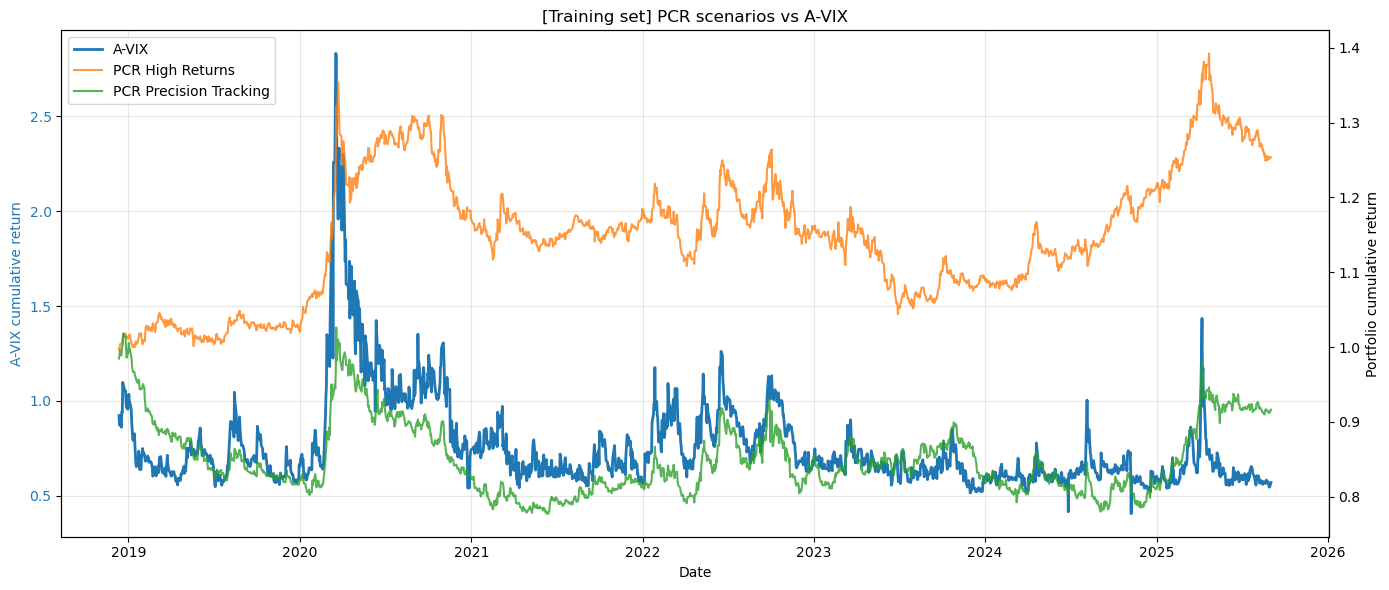

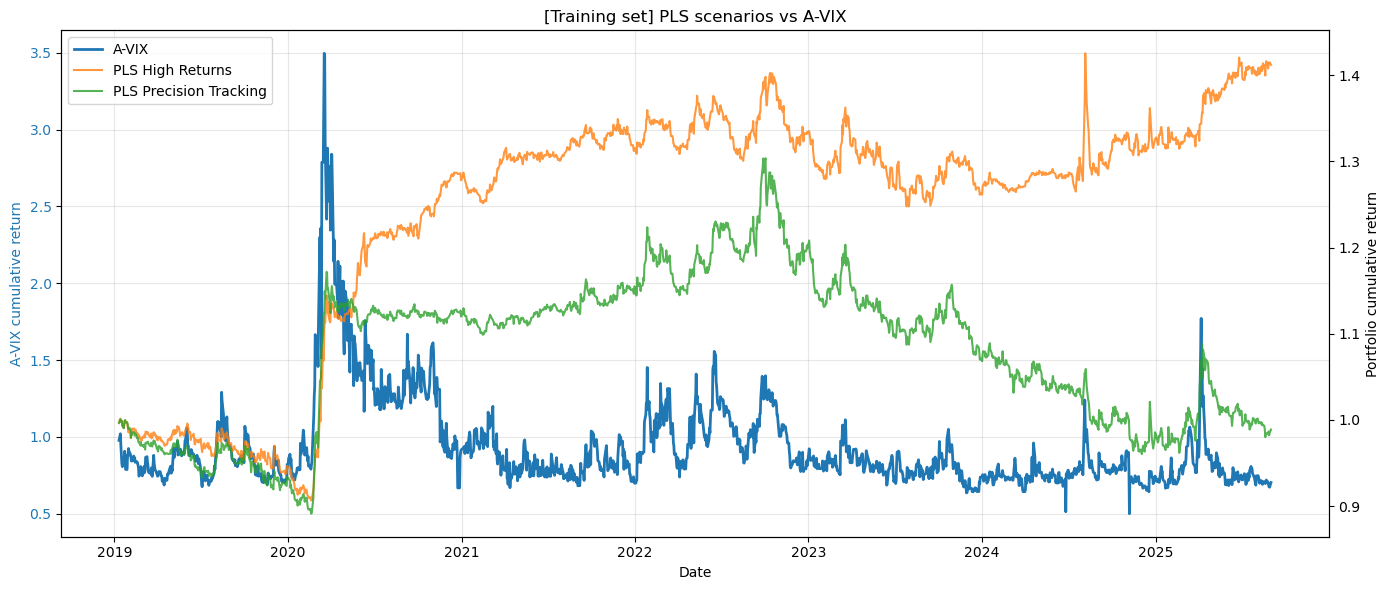

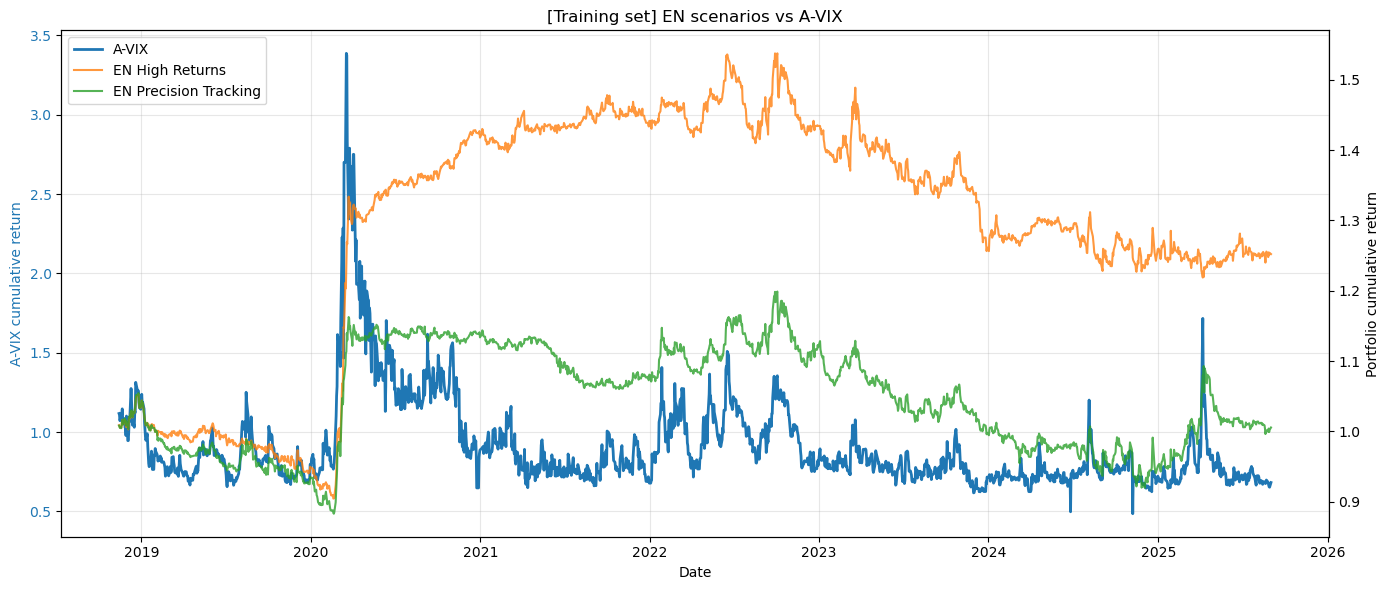

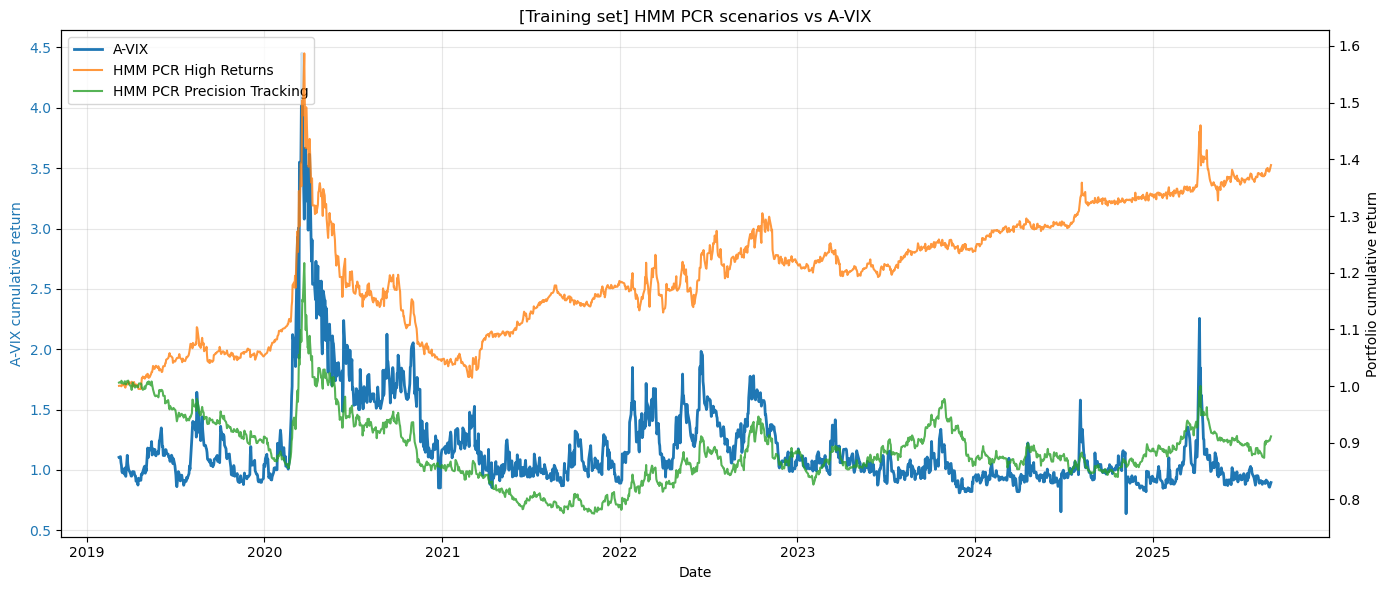

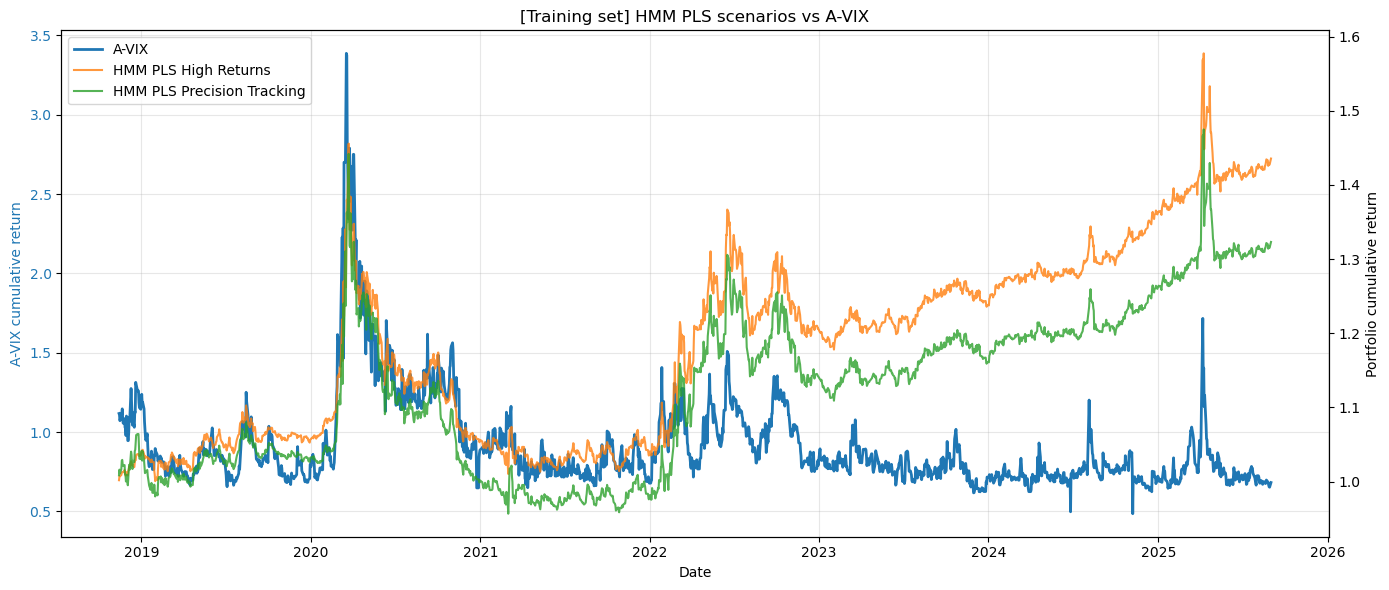

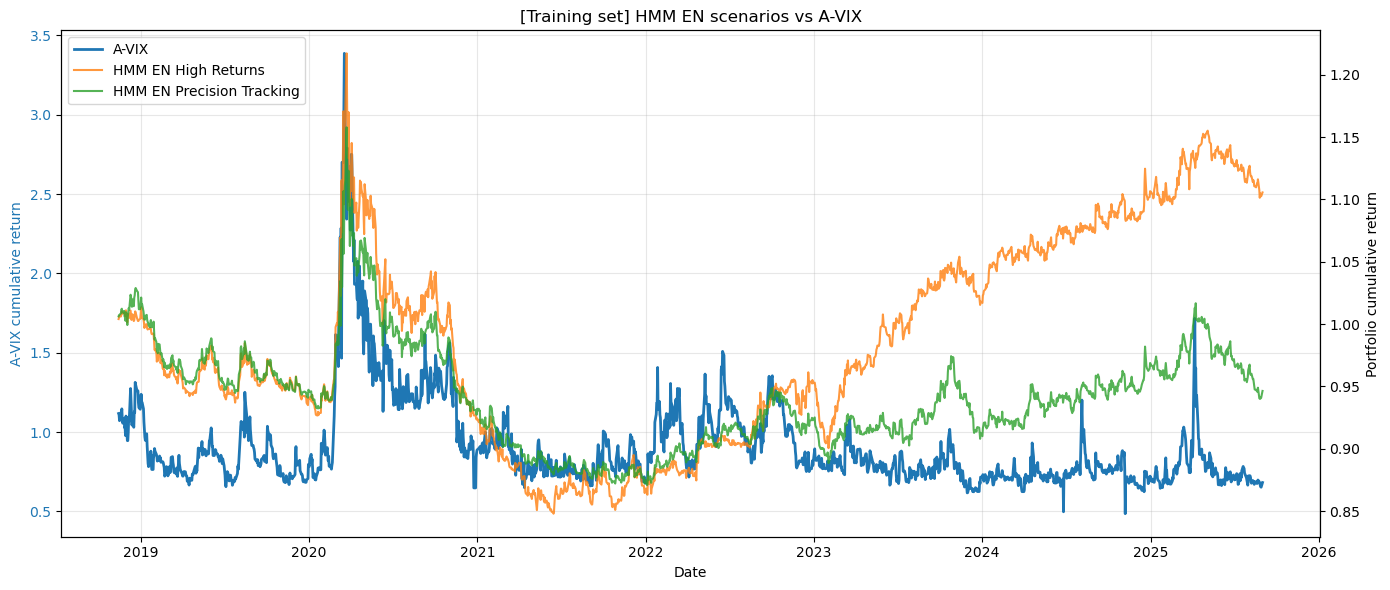

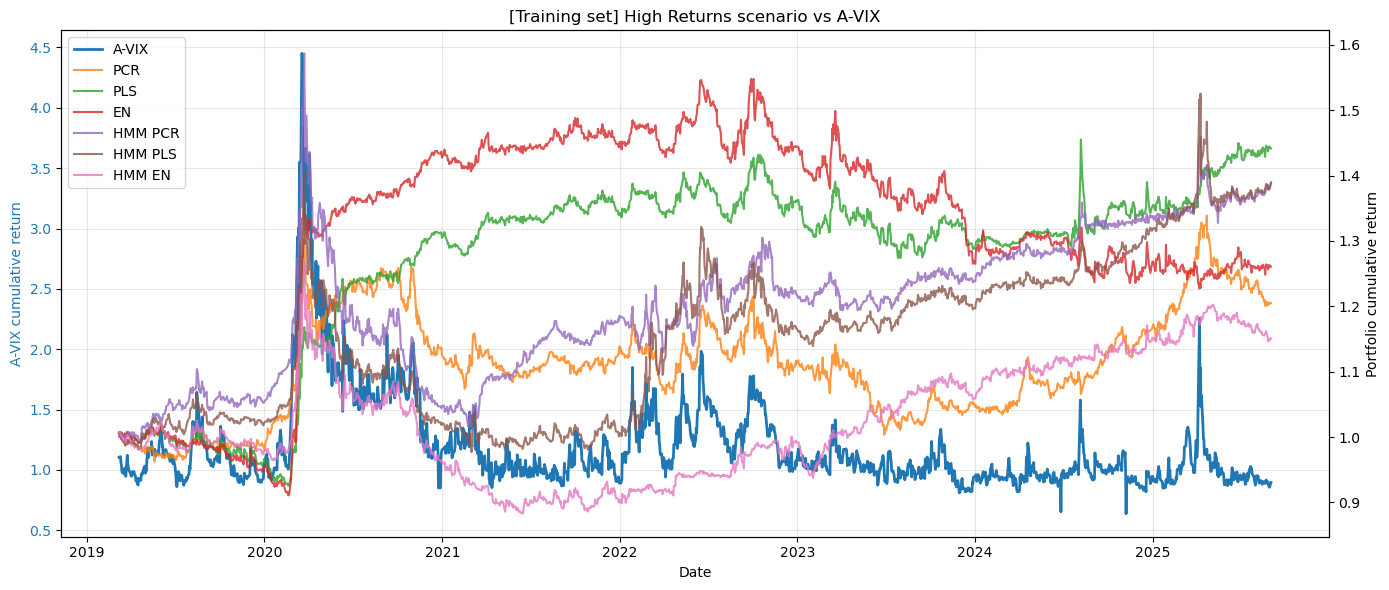

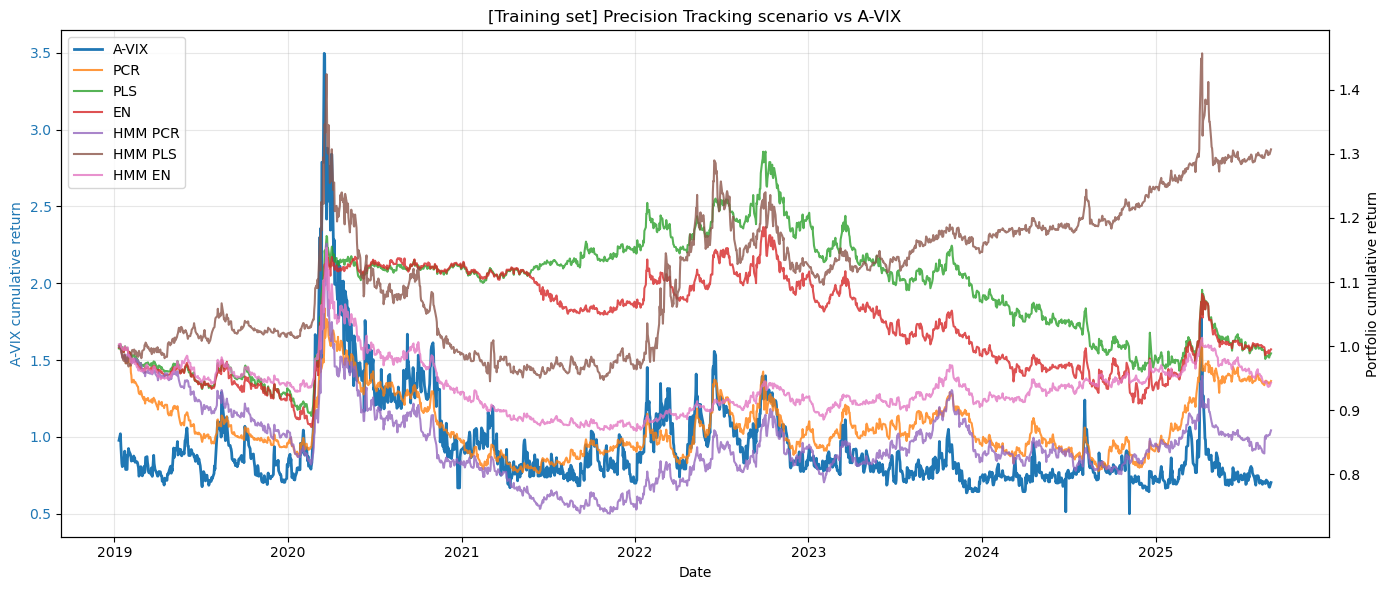

In [22]:
# Train set
if PLOT_GRAPH ==True:
    # (a) scenarios of each algorithm
    focused_plot_multiple('[Training set] PCR scenarios',[
        (train_pcr_high_returns,'PCR High Returns'),
        (train_pcr_high_fidelity,'PCR Precision Tracking'),
    ],y,TRAIN_START,TRAIN_END)

    focused_plot_multiple('[Training set] PLS scenarios',[
        (train_pls_high_returns,'PLS High Returns'),
        (train_pls_high_fidelity,'PLS Precision Tracking'),
    ],y,TRAIN_START,TRAIN_END)

    focused_plot_multiple('[Training set] EN scenarios',[
        (train_en_high_returns,'EN High Returns'),
        (train_en_high_fidelity,'EN Precision Tracking'),
    ],y,TRAIN_START,TRAIN_END)

    focused_plot_multiple('[Training set] HMM PCR scenarios',[
        (train_hmm_pcr_high_returns,'HMM PCR High Returns'),
        (train_hmm_pcr_high_fidelity,'HMM PCR Precision Tracking'),
    ],y,TRAIN_START,TRAIN_END)

    focused_plot_multiple('[Training set] HMM PLS scenarios',[
        (train_hmm_pls_high_returns,'HMM PLS High Returns'),
        (train_hmm_pls_high_fidelity,'HMM PLS Precision Tracking'),
    ],y,TRAIN_START,TRAIN_END)

    focused_plot_multiple('[Training set] HMM EN scenarios',[
        (train_hmm_en_high_returns,'HMM EN High Returns'),
        (train_hmm_en_high_fidelity,'HMM EN Precision Tracking'),
    ],y,TRAIN_START,TRAIN_END)

    # (b) algorithms of each scenario
    focused_plot_multiple('[Training set] High Returns scenario',[
        (train_pcr_high_returns,'PCR'),
        (train_pls_high_returns,'PLS'),
        (train_en_high_returns,'EN'),
        (train_hmm_pcr_high_returns,'HMM PCR'),
        (train_hmm_pls_high_returns,'HMM PLS'),
        (train_hmm_en_high_returns,'HMM EN'),
    ],y,TRAIN_START,TRAIN_END)

    focused_plot_multiple('[Training set] Precision Tracking scenario',[
        (train_pcr_high_fidelity,'PCR'),
        (train_pls_high_fidelity,'PLS'),
        (train_en_high_fidelity,'EN'),
        (train_hmm_pcr_high_fidelity,'HMM PCR'),
        (train_hmm_pls_high_fidelity,'HMM PLS'),
        (train_hmm_en_high_fidelity,'HMM EN'),
    ],y,TRAIN_START,TRAIN_END)


#### **9.2 Test Set results**

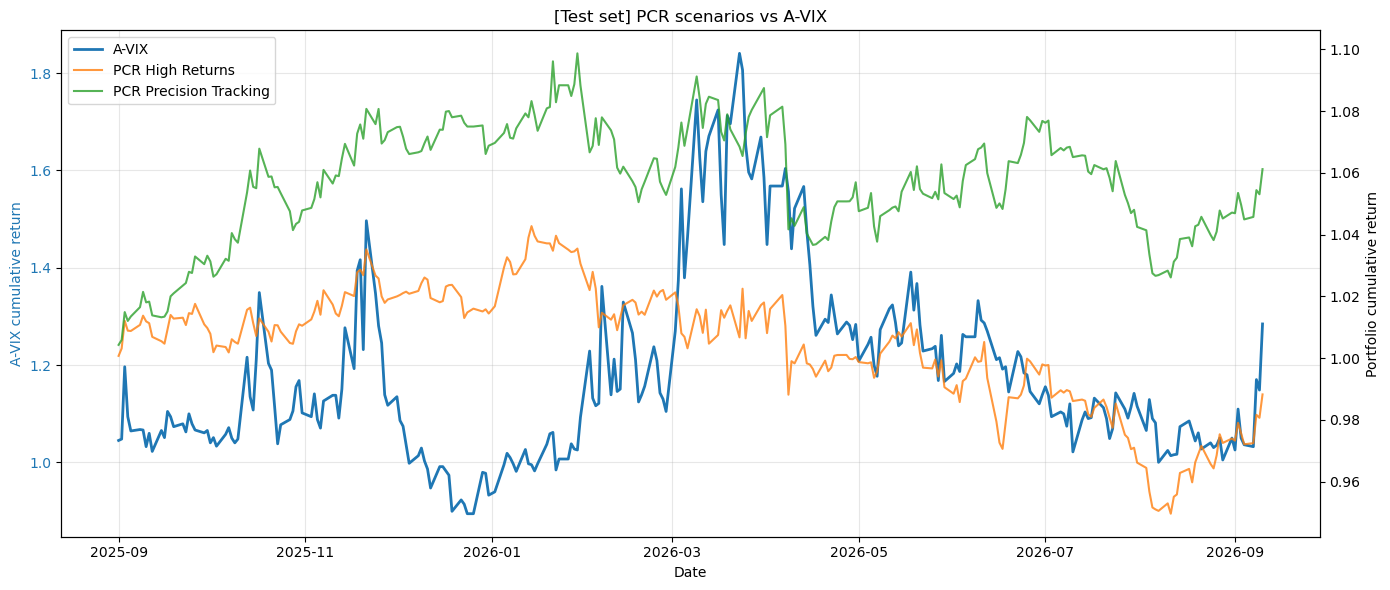

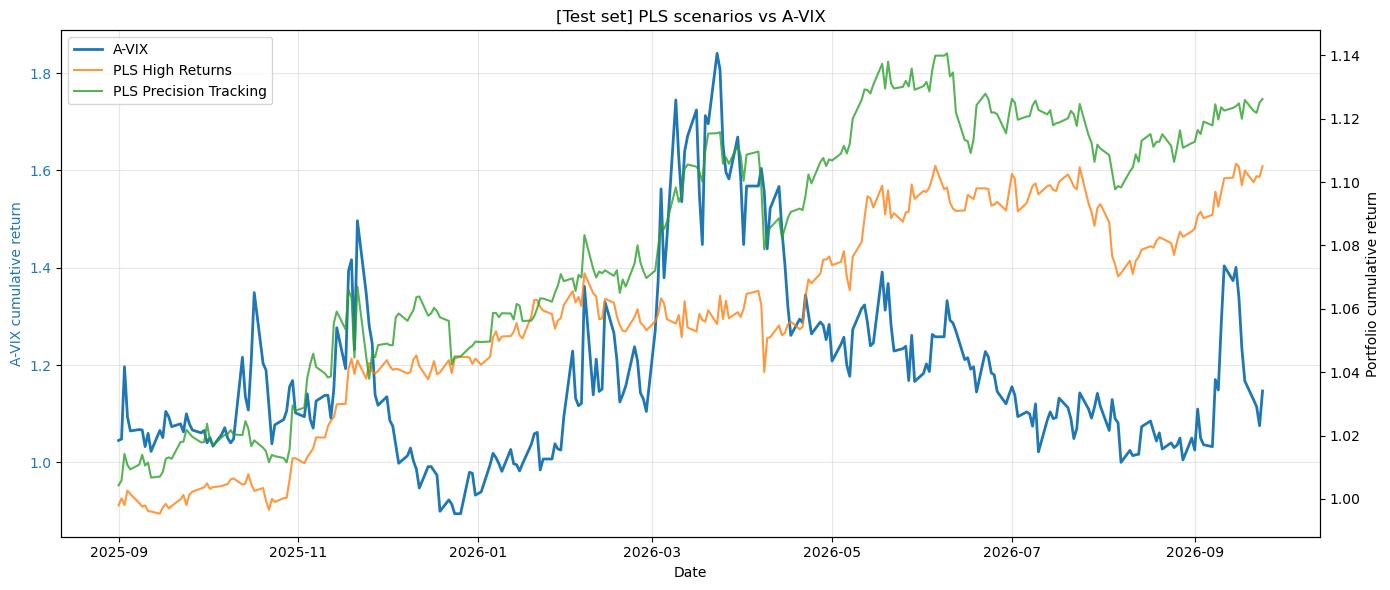

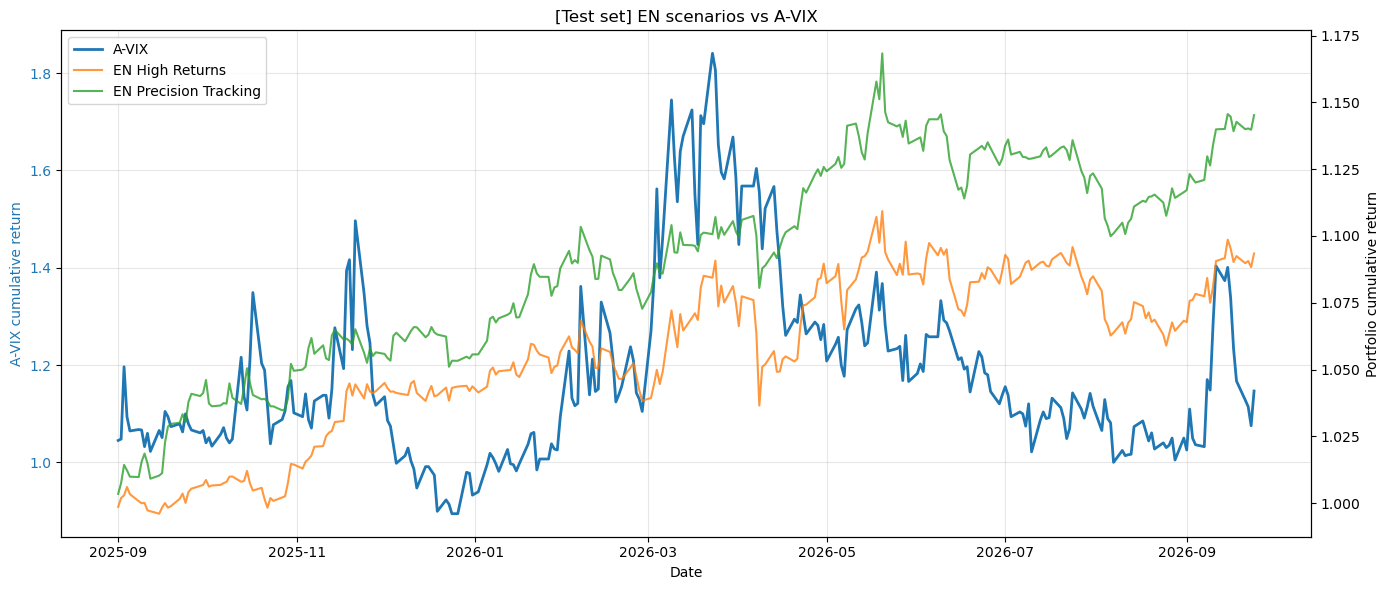

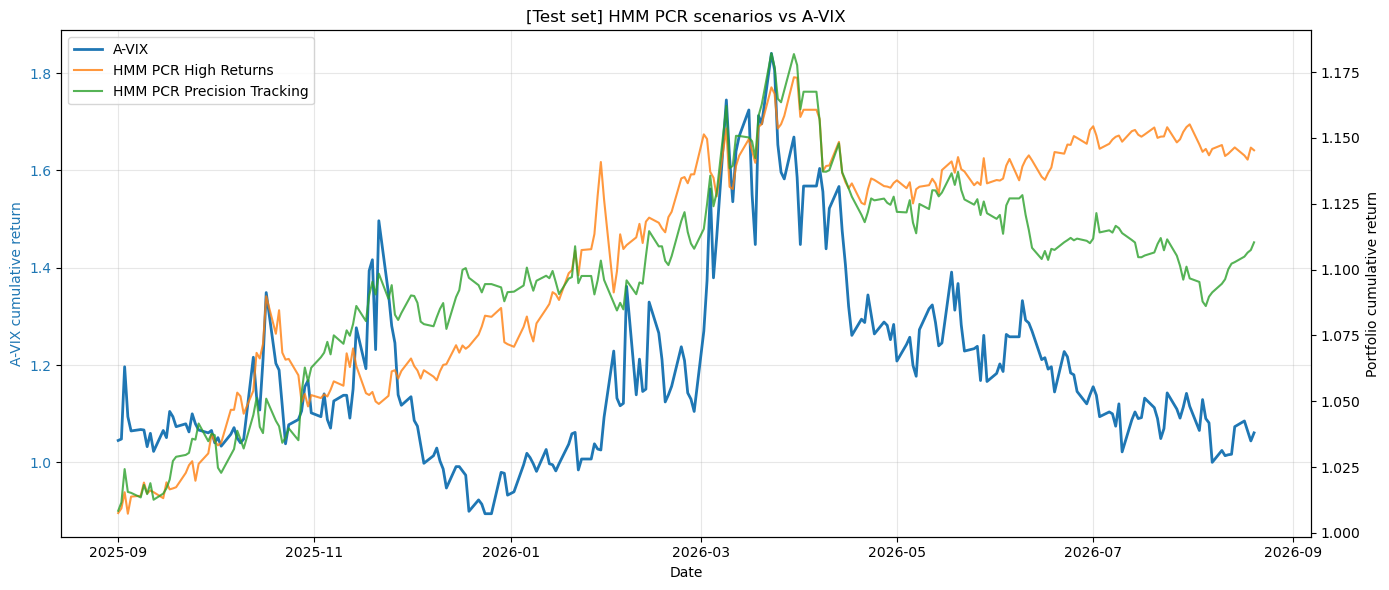

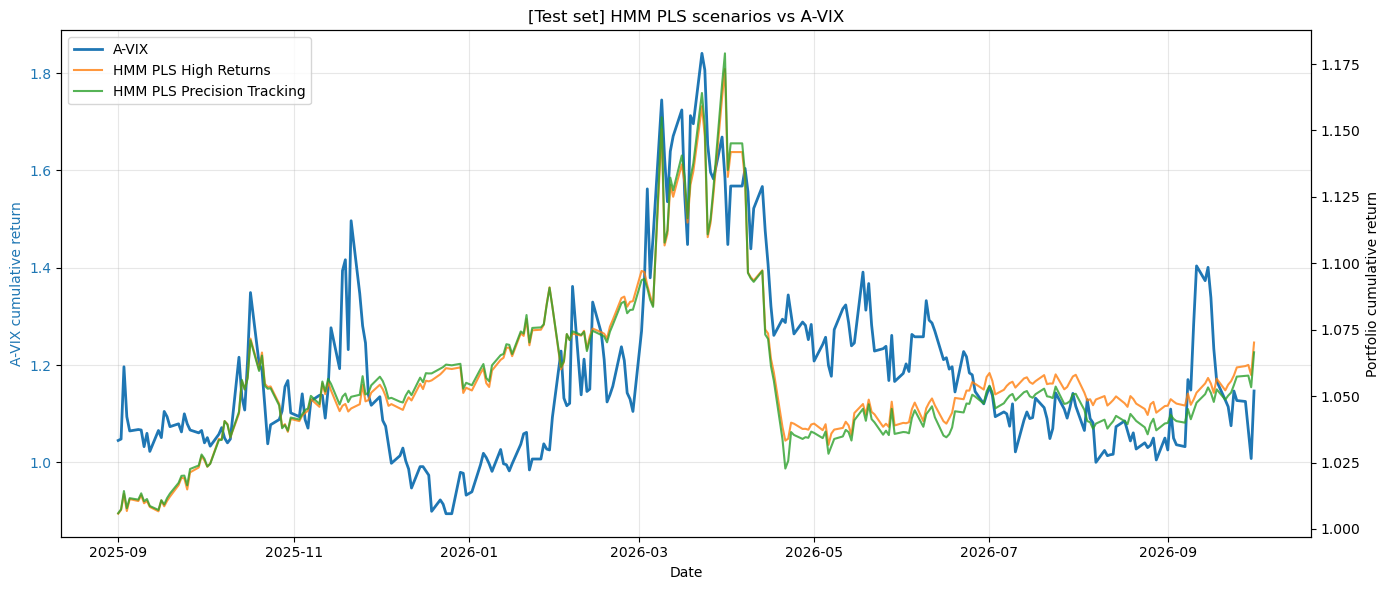

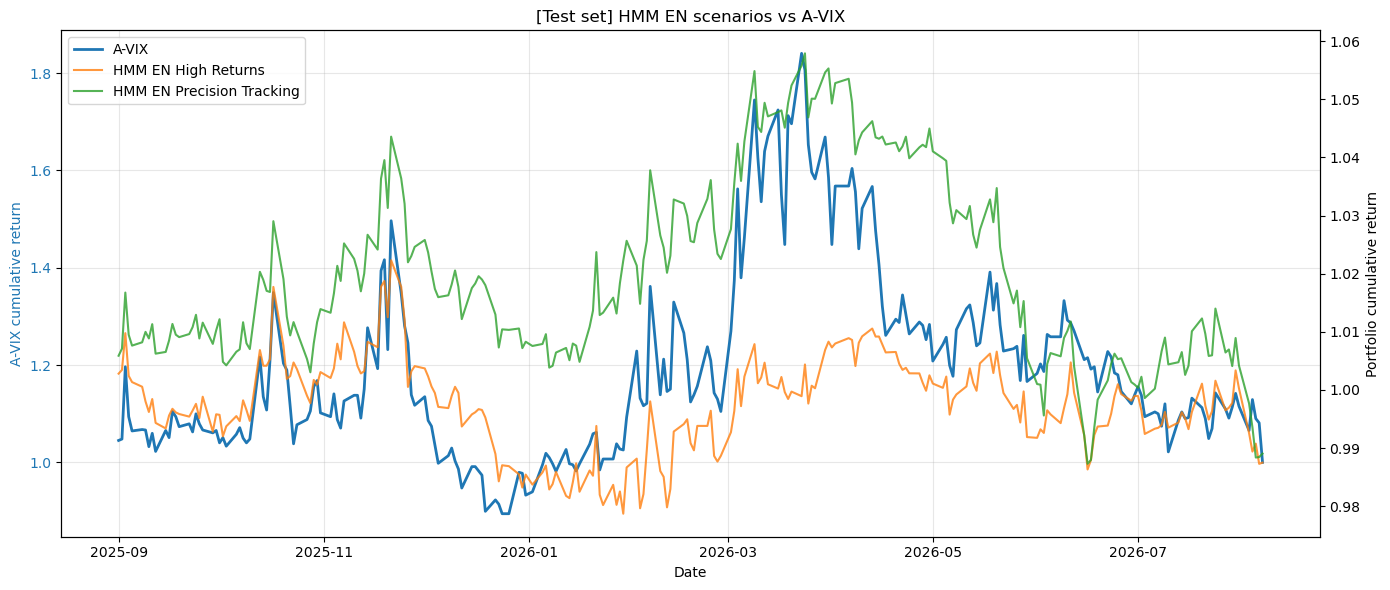

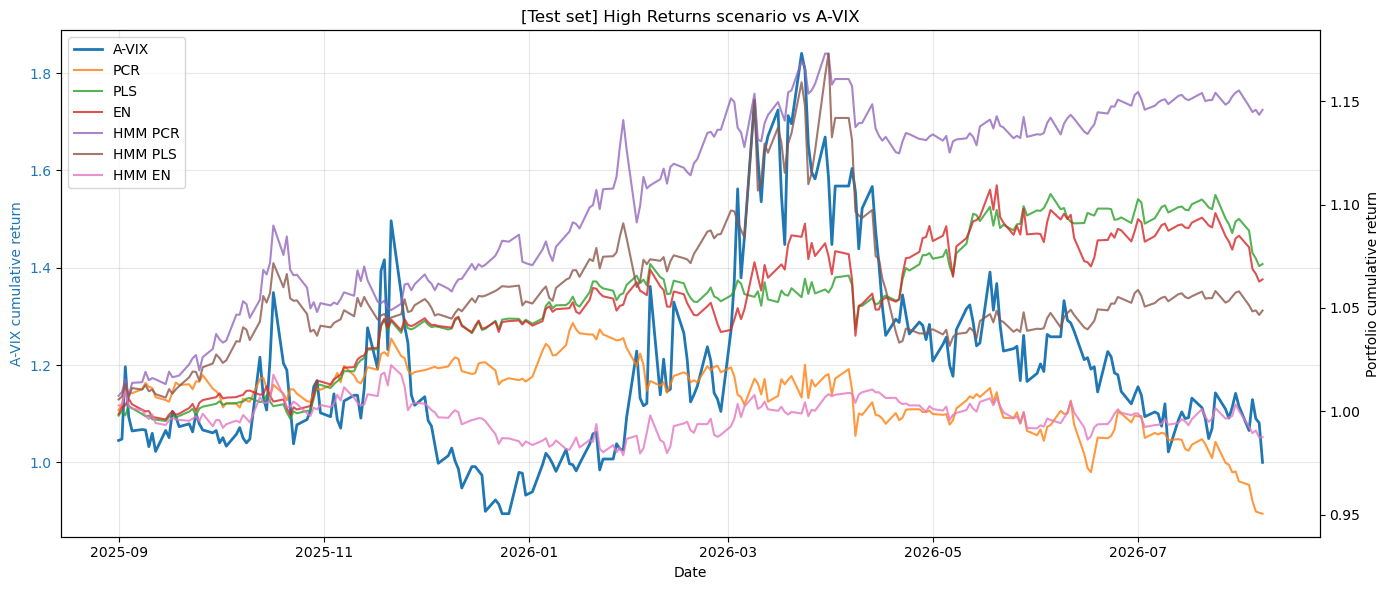

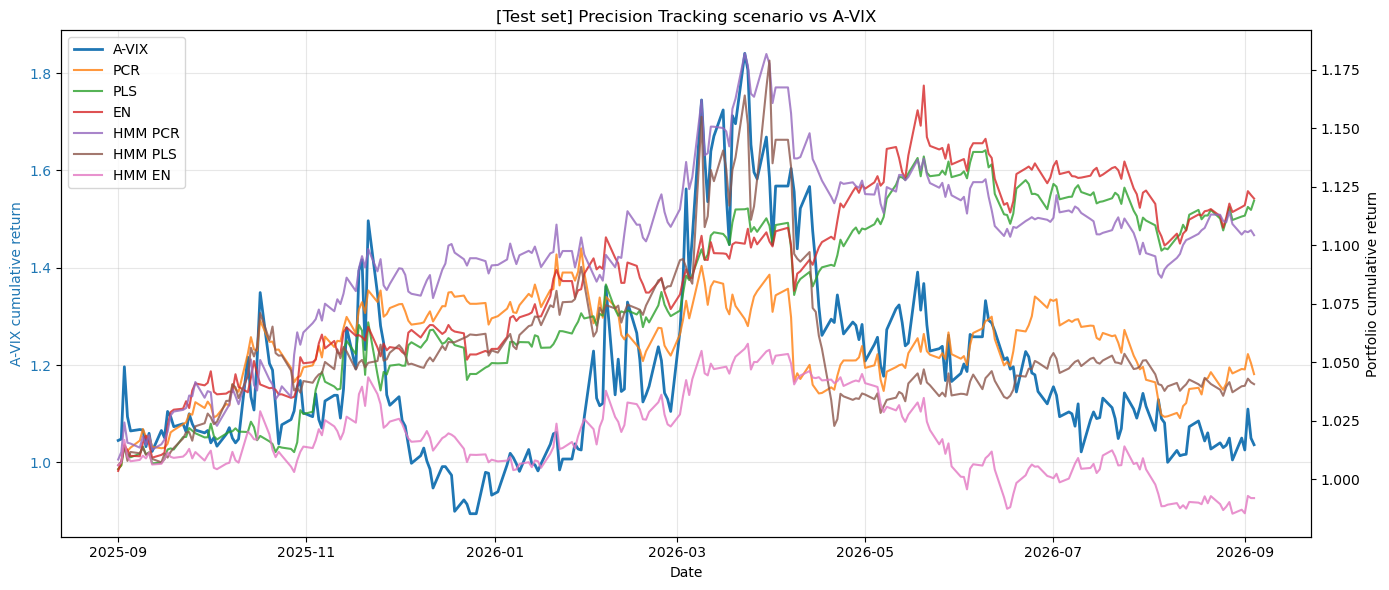

In [23]:
# Test set
if PLOT_GRAPH ==True:
    # (a) scenarios of each algorithm
    focused_plot_multiple('[Test set] PCR scenarios',[
        (test_pcr_high_returns,'PCR High Returns'),
        (test_pcr_high_fidelity,'PCR Precision Tracking'),
    ],y,TEST_START,TEST_END)

    focused_plot_multiple('[Test set] PLS scenarios',[
        (test_pls_high_returns,'PLS High Returns'),
        (test_pls_high_fidelity,'PLS Precision Tracking'),
    ],y,TEST_START,TEST_END)

    focused_plot_multiple('[Test set] EN scenarios',[
        (test_en_high_returns,'EN High Returns'),
        (test_en_high_fidelity,'EN Precision Tracking'),
    ],y,TEST_START,TEST_END)

    focused_plot_multiple('[Test set] HMM PCR scenarios',[
        (test_hmm_pcr_high_returns,'HMM PCR High Returns'),
        (test_hmm_pcr_high_fidelity,'HMM PCR Precision Tracking'),
    ],y,TEST_START,TEST_END)

    focused_plot_multiple('[Test set] HMM PLS scenarios',[
        (test_hmm_pls_high_returns,'HMM PLS High Returns'),
        (test_hmm_pls_high_fidelity,'HMM PLS Precision Tracking'),
    ],y,TEST_START,TEST_END)

    focused_plot_multiple('[Test set] HMM EN scenarios',[
        (test_hmm_en_high_returns,'HMM EN High Returns'),
        (test_hmm_en_high_fidelity,'HMM EN Precision Tracking'),
    ],y,TEST_START,TEST_END)

    # (b) algorithms of each scenario
    focused_plot_multiple('[Test set] High Returns scenario',[
        (test_pcr_high_returns,'PCR'),
        (test_pls_high_returns,'PLS'),
        (test_en_high_returns,'EN'),
        (test_hmm_pcr_high_returns,'HMM PCR'),
        (test_hmm_pls_high_returns,'HMM PLS'),
        (test_hmm_en_high_returns,'HMM EN'),
    ],y,TEST_START,TEST_END)

    focused_plot_multiple('[Test set] Precision Tracking scenario',[
        (test_pcr_high_fidelity,'PCR'),
        (test_pls_high_fidelity,'PLS'),
        (test_en_high_fidelity,'EN'),
        (test_hmm_pcr_high_fidelity,'HMM PCR'),
        (test_hmm_pls_high_fidelity,'HMM PLS'),
        (test_hmm_en_high_fidelity,'HMM EN'),
    ],y,TEST_START,TEST_END)

#### **9.3 Full Evaluation Set results**

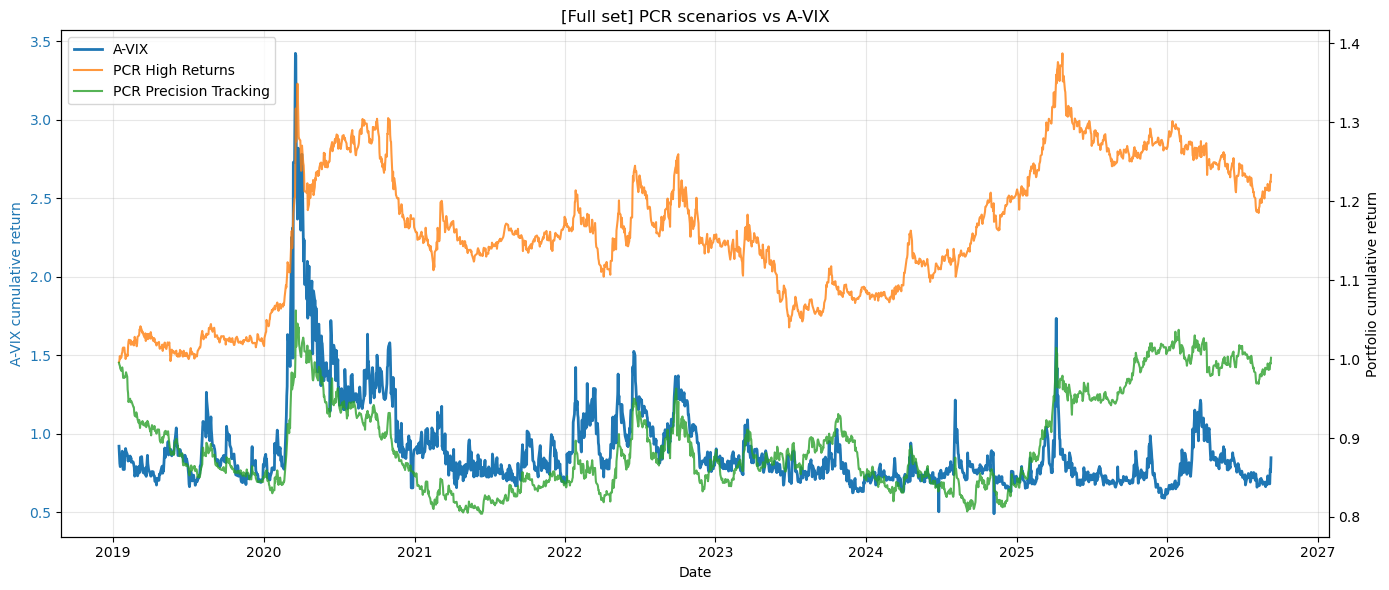

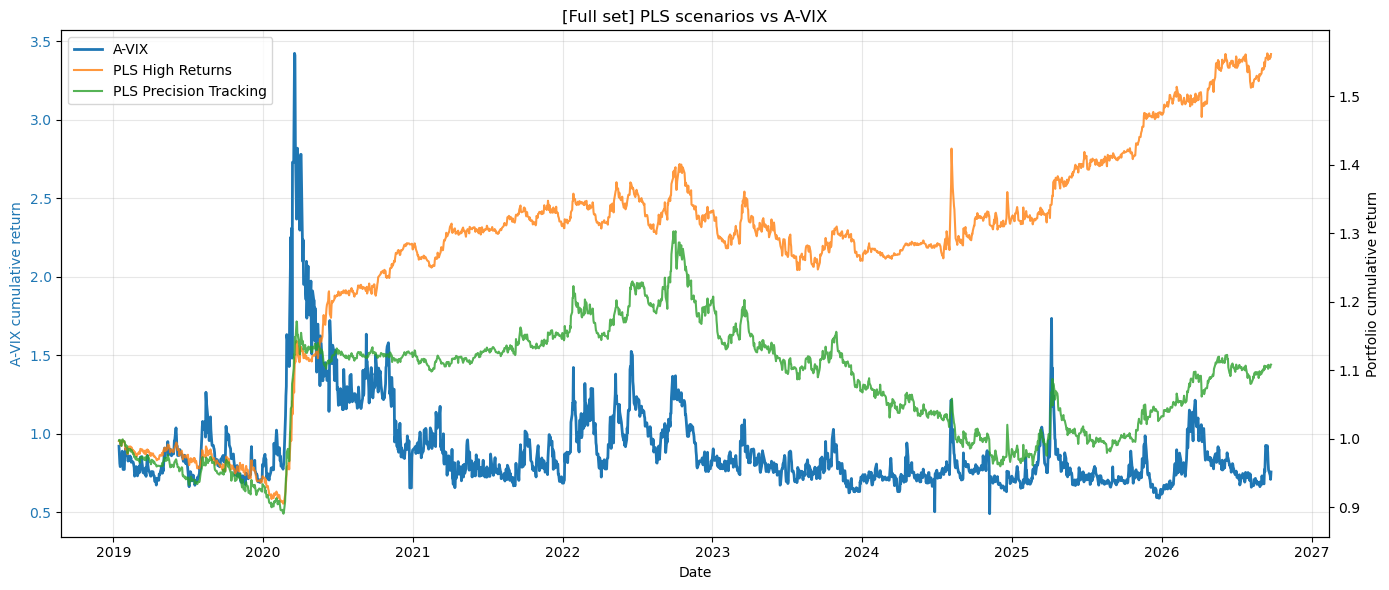

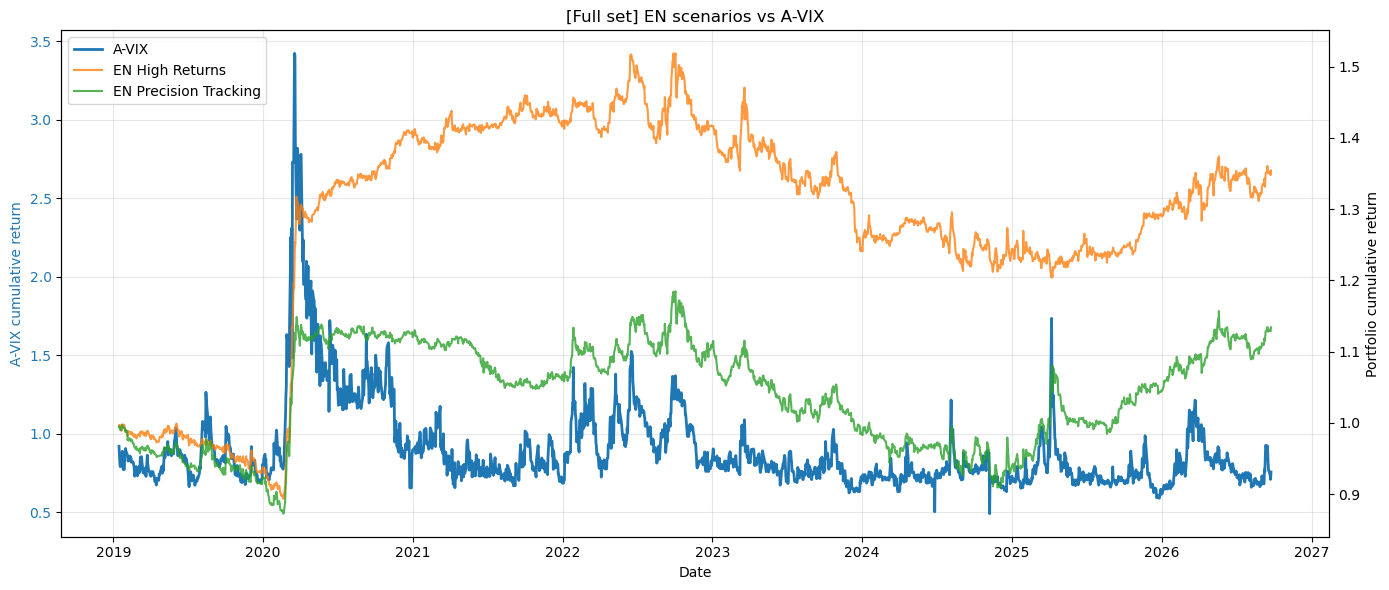

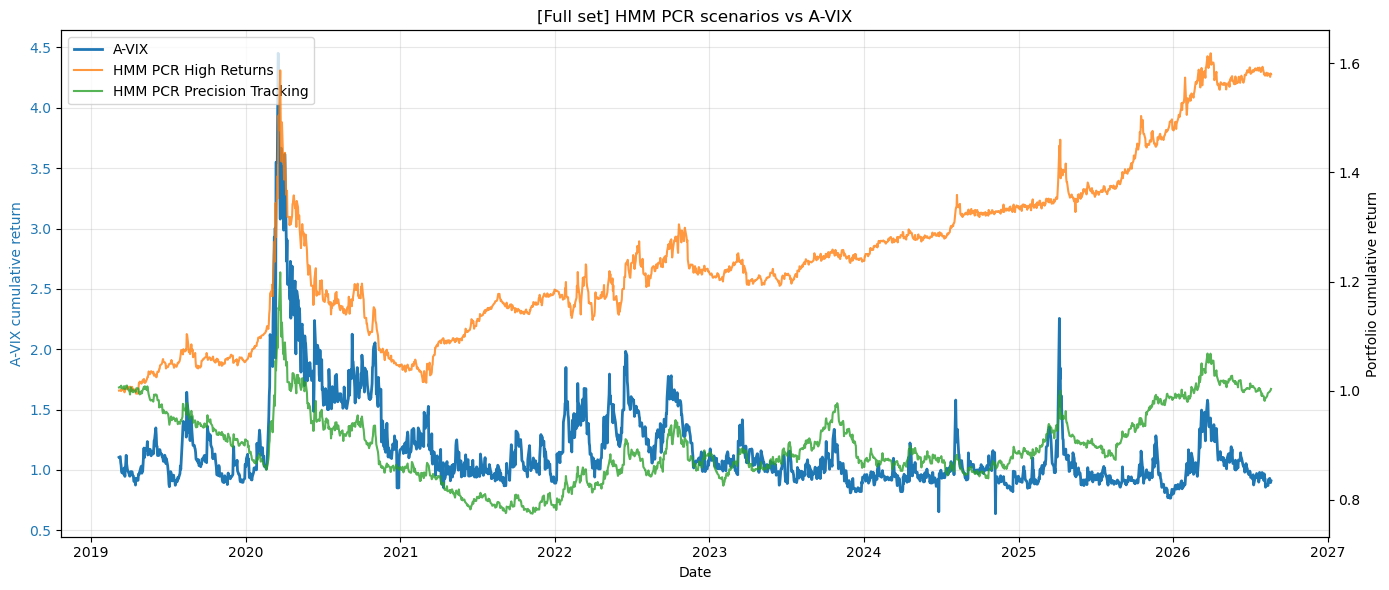

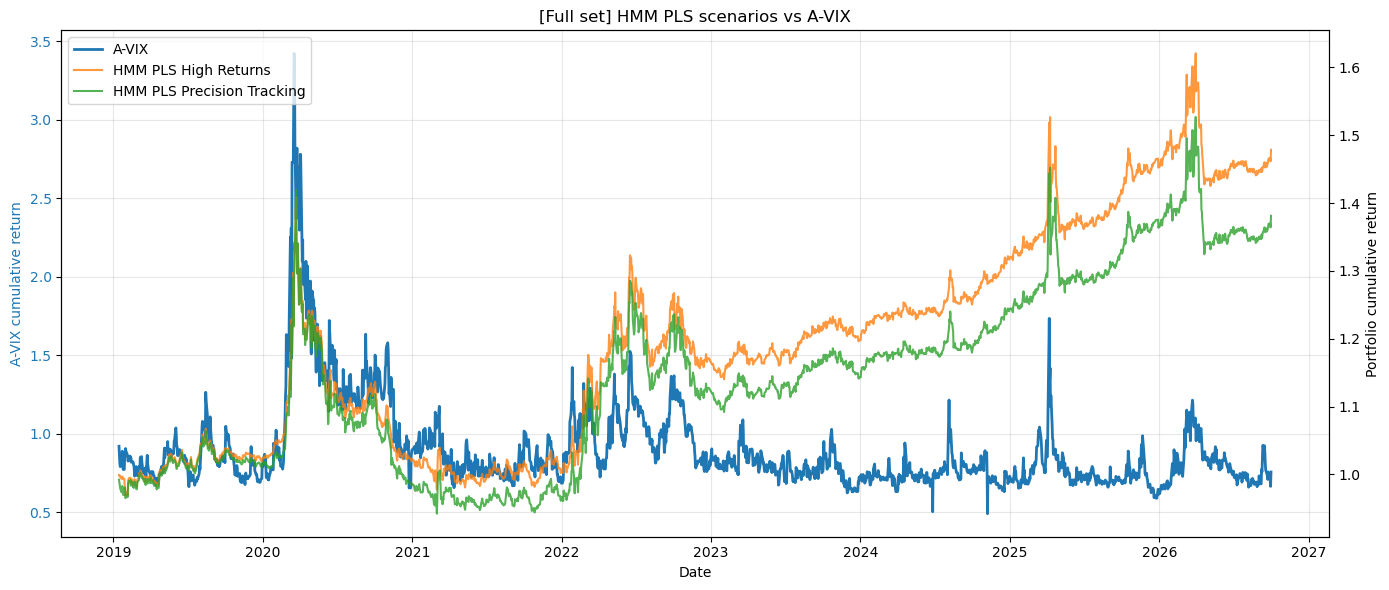

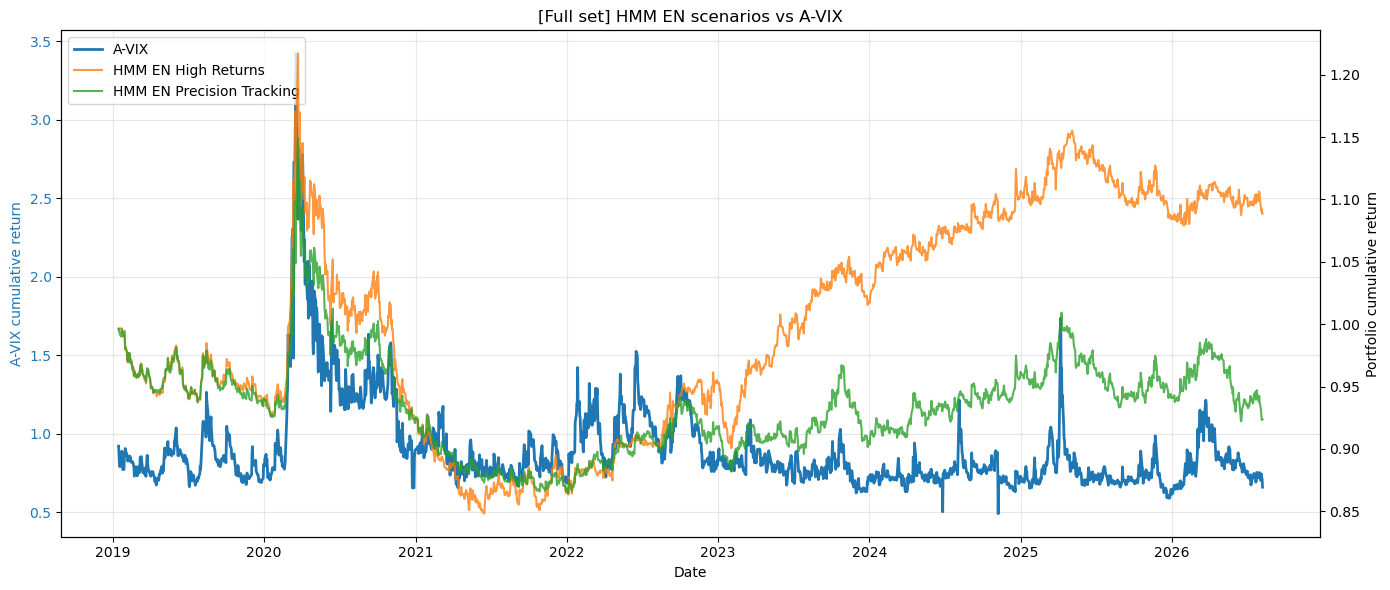

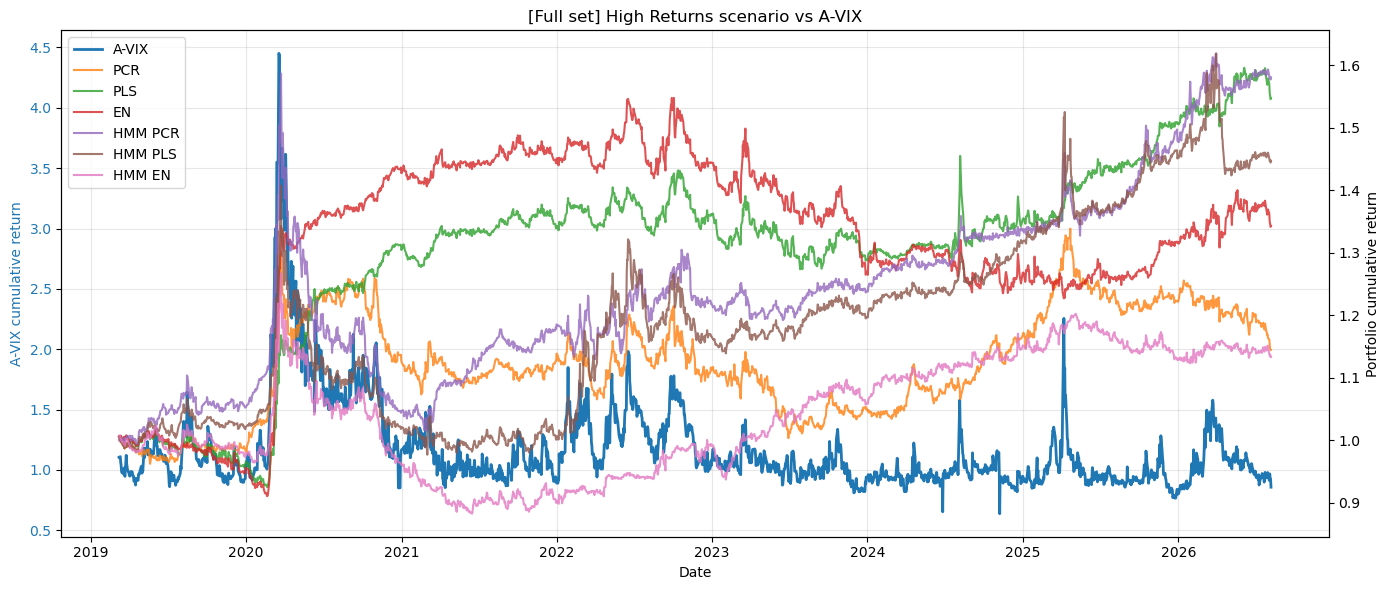

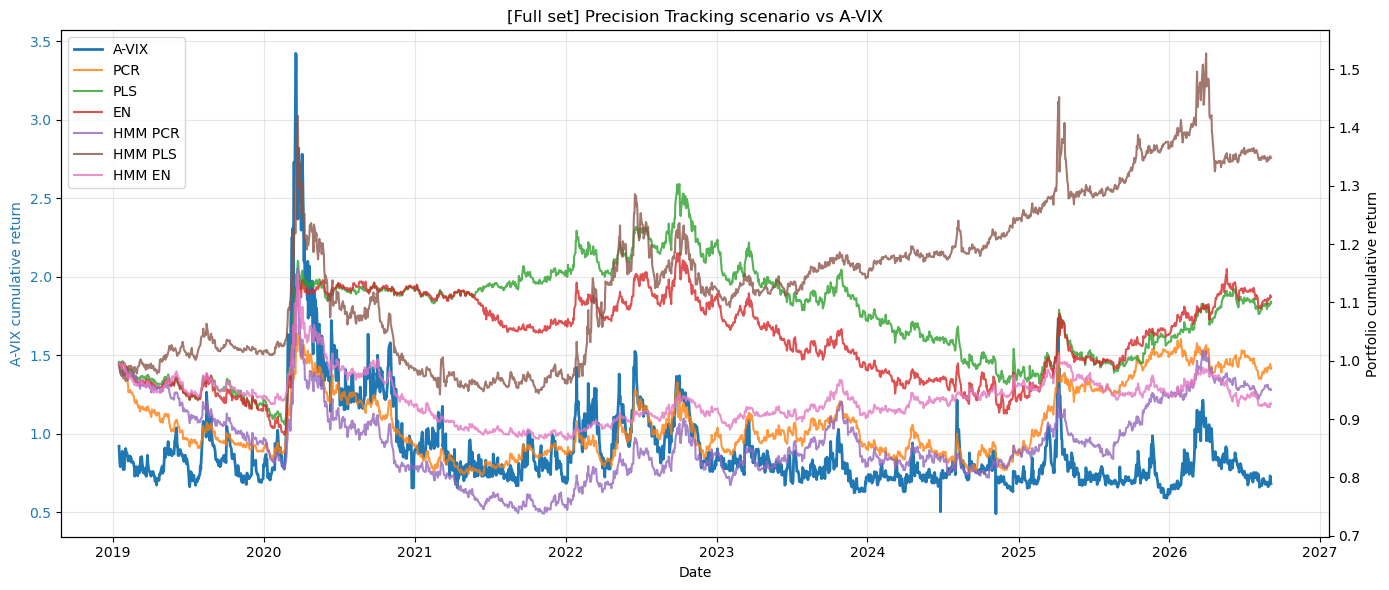

In [24]:
# Full set
if PLOT_GRAPH ==True:
    # (a) scenarios of each algorithm
    focused_plot_multiple('[Full set] PCR scenarios',[
        (full_pcr_high_returns,'PCR High Returns'),
        (full_pcr_high_fidelity,'PCR Precision Tracking'),
    ],y,EVAL_START,EVAL_END)

    focused_plot_multiple('[Full set] PLS scenarios',[
        (full_pls_high_returns,'PLS High Returns'),
        (full_pls_high_fidelity,'PLS Precision Tracking'),
    ],y,EVAL_START,EVAL_END)

    focused_plot_multiple('[Full set] EN scenarios',[
        (full_en_high_returns,'EN High Returns'),
        (full_en_high_fidelity,'EN Precision Tracking'),
    ],y,EVAL_START,EVAL_END)

    focused_plot_multiple('[Full set] HMM PCR scenarios',[
        (full_hmm_pcr_high_returns,'HMM PCR High Returns'),
        (full_hmm_pcr_high_fidelity,'HMM PCR Precision Tracking'),
    ],y,EVAL_START,EVAL_END)

    focused_plot_multiple('[Full set] HMM PLS scenarios',[
        (full_hmm_pls_high_returns,'HMM PLS High Returns'),
        (full_hmm_pls_high_fidelity,'HMM PLS Precision Tracking'),
    ],y,EVAL_START,EVAL_END)

    focused_plot_multiple('[Full set] HMM EN scenarios',[
        (full_hmm_en_high_returns,'HMM EN High Returns'),
        (full_hmm_en_high_fidelity,'HMM EN Precision Tracking'),
    ],y,EVAL_START,EVAL_END)

    # (b) algorithms of each scenario
    focused_plot_multiple('[Full set] High Returns scenario',[
        (full_pcr_high_returns,'PCR'),
        (full_pls_high_returns,'PLS'),
        (full_en_high_returns,'EN'),
        (full_hmm_pcr_high_returns,'HMM PCR'),
        (full_hmm_pls_high_returns,'HMM PLS'),
        (full_hmm_en_high_returns,'HMM EN'),
    ],y,EVAL_START,EVAL_END)

    focused_plot_multiple('[Full set] Precision Tracking scenario',[
        (full_pcr_high_fidelity,'PCR'),
        (full_pls_high_fidelity,'PLS'),
        (full_en_high_fidelity,'EN'),
        (full_hmm_pcr_high_fidelity,'HMM PCR'),
        (full_hmm_pls_high_fidelity,'HMM PLS'),
        (full_hmm_en_high_fidelity,'HMM EN'),
    ],y,EVAL_START,EVAL_END)

#### **9.4 BEAR Benchmark**

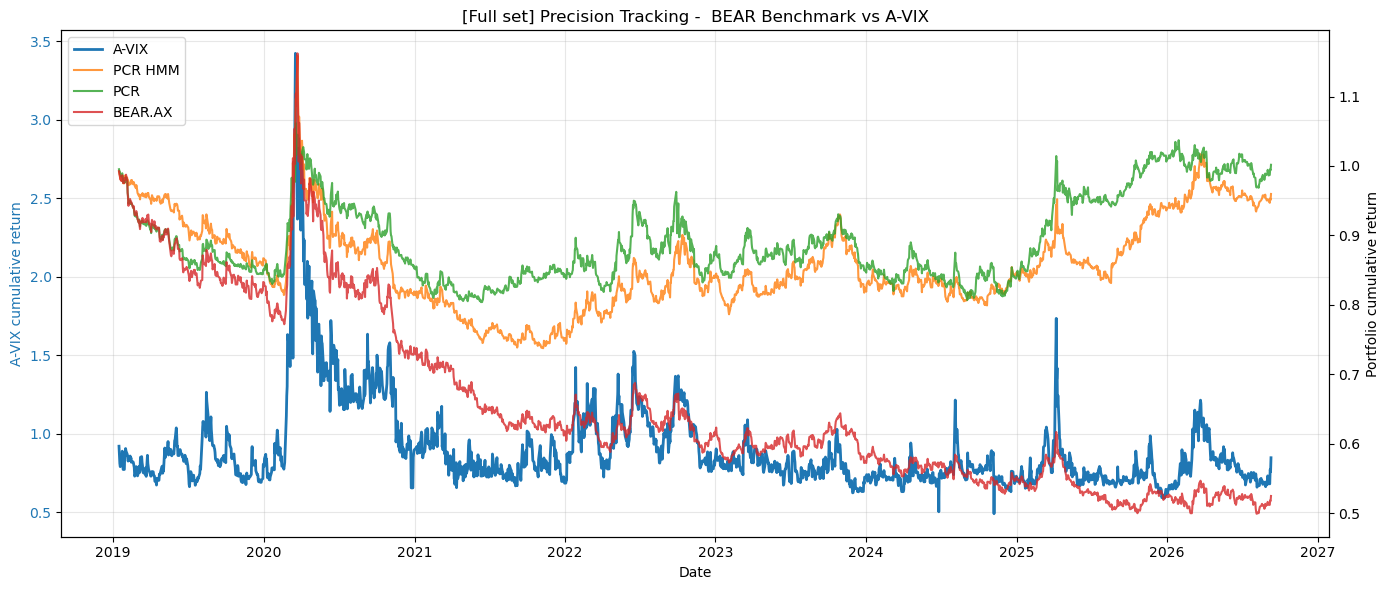

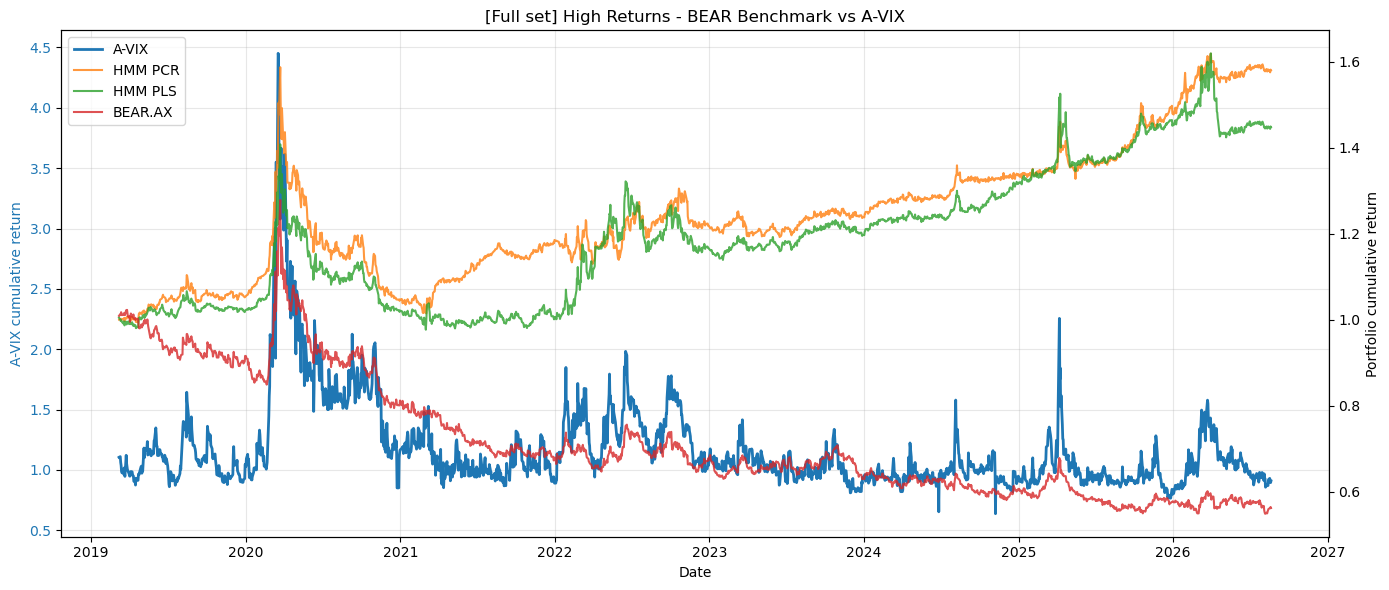

In [25]:
# Benchmark
if PLOT_GRAPH ==True:
    BEAR_returns = screened_returns['BEAR.AX']
    UVXY_returns = screened_returns['UVXY']
    negative_STW = -1* screened_returns['STW.AX']
    negative_OZF = -1* screened_returns['OZF.AX']
    
    focused_plot_multiple('[Full set] Precision Tracking -  BEAR Benchmark',[
        (full_hmm_pcr_high_fidelity,'PCR HMM'),
        (full_pcr_high_fidelity,'PCR'),
        (BEAR_returns,'BEAR.AX'),
        #(UVXY_returns,'UVXY'),
        #(negative_STW,'-STW.AX'),
        #(negative_OZF,'-OZF.AX'),
    ],y,EVAL_START,EVAL_END)
    
    focused_plot_multiple('[Full set] High Returns - BEAR Benchmark',[
        (full_hmm_pcr_high_returns,'HMM PCR'),
        (full_hmm_pls_high_returns,'HMM PLS'),
        (BEAR_returns,'BEAR.AX'),
        #(UVXY_returns,'UVXY'),
        #(negative_STW,'-STW.AX'),
        #(negative_OZF,'-OZF.AX'),
    ],y,EVAL_START,EVAL_END)


In [26]:
#### **9.5 UVXY Benchmark**

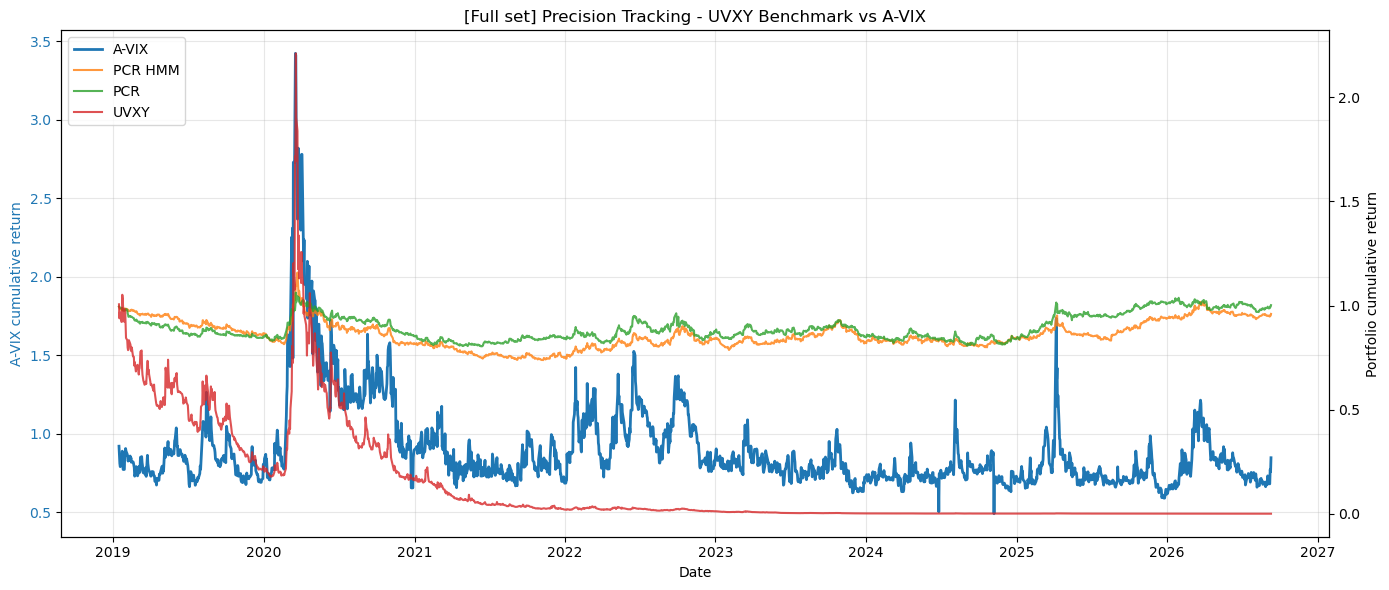

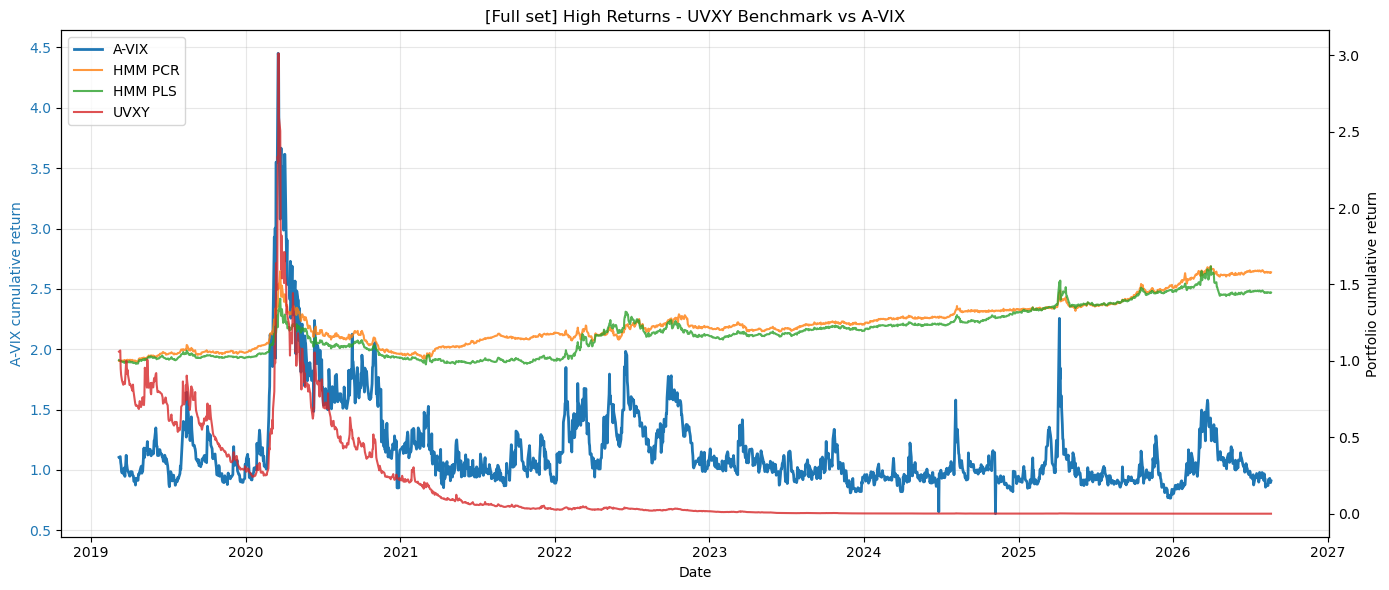

In [27]:
# Benchmark
if PLOT_GRAPH ==True:
   
    focused_plot_multiple('[Full set] Precision Tracking - UVXY Benchmark',[
        (full_hmm_pcr_high_fidelity,'PCR HMM'),
        (full_pcr_high_fidelity,'PCR'),
        #(BEAR_returns,'BEAR.AX'),
        (UVXY_returns,'UVXY'),
        #(negative_STW,'-STW.AX'),
        #(negative_OZF,'-OZF.AX'),
    ],y,EVAL_START,EVAL_END)
    
    focused_plot_multiple('[Full set] High Returns - UVXY Benchmark',[
        (full_hmm_pcr_high_returns,'HMM PCR'),
        (full_hmm_pls_high_returns,'HMM PLS'),
        #(BEAR_returns,'BEAR.AX'),
        (UVXY_returns,'UVXY'),
        #(negative_STW,'-STW.AX'),
        #(negative_OZF,'-OZF.AX'),
    ],y,EVAL_START,EVAL_END)